# PHYS20762 - Project - Monte Carlo Techniques

Nachiketh Rarichandran <br>
University of Manchester <br>
May 2026

## Abstract

This project uses Monte Carlo methods to simulate the transport of thermal neutrons through shielding materials. The random number generation was first validated using `numpy.random.uniform()`, including checks of uniformity, three-dimensional point distributions, and comparison with the RANDSSP generator, which showed spectral artefacts. Exponential path-length sampling was then implemented using inverse transform sampling and used to reproduce the expected absorption-only attenuation length for water of approximately 45 cm.

The simulation was extended to generate isotropic scattering directions and random neutron steps. These components were combined into a slab transport model for water, lead, and graphite, where neutrons enter at x = 0 and are tracked until absorption, reflection, or transmission. The material macroscopic cross-sections and total mean free paths were calculated from the data provided in the project brief. Transport rates were calculated for L = 10 cm and then studied as a function of slab thickness. Effective attenuation lengths were obtained by fitting the transmission rates against thickness. As an extension, the Woodcock method was implemented for two adjacent slabs and validated against the single-material transport model.

## 1. Introduction

Neutrons passing through a shielding material can either be absorbed, scattered, reflected, or transmitted depending on the microscopic interaction probabilities of the material. These interaction probabilities are described by the absorption and scattering cross-sections, which can be converted into macroscopic cross-sections using the material density and molar mass. The macroscopic cross-sections then determine the mean free path of a neutron in the material, which is the average distance travelled before an interaction occurs.

In this project, Monte Carlo methods are used to simulate the transport of thermal neutrons through shielding layers made of water, lead, and graphite. Monte Carlo techniques are well suited to this problem because neutron transport is inherently probabilistic: the distance to the next interaction is randomly sampled from an exponential distribution, while scattering directions are randomly sampled from an isotropic angular distribution. By repeating this process for many neutrons, the average absorption, reflection, and transmission behaviour of the shielding material can be estimated statistically.

### 1.1 Code Initialization

Before developing the Monte Carlo simulation, the required Python modules are imported. 
`numpy` is used for numerical calculations and random number generation, while `matplotlib` is used for plotting the generated distributions and simulation results. The `time` module is included to measure the runtime of the final simulation, and `Axes3D` is imported to allow three-dimensional visualisation of randomly generated points and neutron paths.

In [1]:
# Initialisation
import numpy as np
import matplotlib.pyplot as plt
import time
from mpl_toolkits.mplot3d import Axes3D

The project brief specifies an expected runtime for the full notebook, so a timer is started here to measure the total execution time. The elapsed time will be calculated at the end of the notebook to check that the full simulation runs efficiently.

In [2]:
# Starting the timer for the full notebook
start_time = time.time()

### 1.2 Material Data

The simulation uses the thermal neutron data provided in the project brief for water, lead, and graphite. The microscopic absorption and scattering cross-sections are given in barns, while the density and molar mass are used later to calculate the number density and macroscopic cross-sections for each material.

The code below displays these parameters in a table.

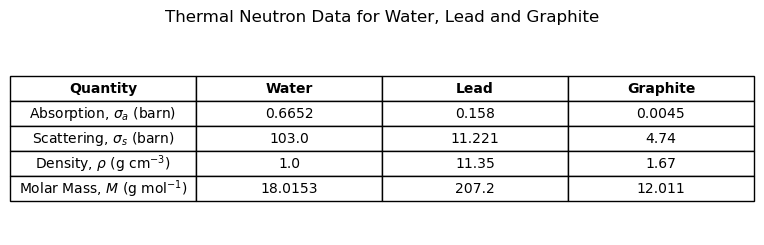

In [3]:
# Defining the material names as headers.
material_names = ['Water', 'Lead', 'Graphite']
# This is the data as shown in th eproject brief.
table_data = [
    ['Absorption, $\\sigma_a$ (barn)', 0.6652, 0.158, 0.0045],
    ['Scattering, $\\sigma_s$ (barn)', 103.0, 11.221, 4.74],
    ['Density, $\\rho$ (g cm$^{-3}$)', 1.00, 11.35, 1.67],
    ['Molar Mass, $M$ (g mol$^{-1}$)', 18.0153, 207.2, 12.011]
]

# Creating the figure
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.axis('off')

# Creating the table
table = ax.table(cellText = table_data, colLabels = ['Quantity'] + material_names, cellLoc = 'center', loc = 'center')

# Formatting the table
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

# Making the header row bold
for col in range(len(material_names) + 1):
    table[(0, col)].set_text_props(weight = 'bold')
    
# Giving a title
plt.title('Thermal Neutron Data for Water, Lead and Graphite', pad = 15)
plt.show()

These values are treated as the fixed input parameters for the rest of the neutron transport simulation.

## 2. Testing Random Number Generation

The notebook first validates the random number generation used in the simulation by testing the uniformity of `numpy.random.uniform()` and comparing it with a poor random number generator that exhibits spectral issues.

### 2.1 Convergence of Histogram with Number of Samples

The first step is to check that Python's built-in random number generator can produce numbers uniformly distributed over a chosen range. For this test, random numbers are generated using `numpy.random.uniform()` over the interval 0 ≤ x ≤ 1.

For a truly uniform distribution over an interval from a to b, the theoretical probability density is constant and given by:

\begin{equation}
p(x) = \frac{1}{b-a}
\end{equation}

For the interval used here, a = 0 and b = 1, so this becomes:

\begin{equation}
p(x) = 1
\end{equation}

We set the paramers in this way.

In [4]:
# Defining the list of sample sizes going to be for the histograms.
sample_sizes = [100, 1000, 100000]

# Parameters
a      = 0            # Lower bound
b      = 1            # Upper bound
n_bins = 50           # Number of bins in each histogram

Histograms are produced for three different sample sizes, N = 100, 1000, and 100000, to show how the generated distribution changes as the number of samples increases. The expected probability density is shown as a horizontal red line. The green dashed lines show the approximate 1σ statistical uncertainty expected from Poisson fluctuations in the bin counts.

Since the histogram is made from a finite number of random samples, each bin has a statistical uncertainty. If the random numbers are uniformly distributed, the expected number of samples in each bin is approximately

\begin{equation}
n_{\mathrm{expected}} = \frac{N}{N_{\mathrm{bins}}}
\end{equation}

The uncertainty in the number of counts in each bin is assumed to follow Poisson statistics, so

\begin{equation}
\sigma_n = \sqrt{n_{\mathrm{expected}}}
\end{equation}

However, the histogram is plotted as a probability density rather than raw counts. Since `density=True` normalises the histogram by the total number of samples and the bin width, the uncertainty in the probability density is

\begin{equation}
\sigma_{\mathrm{density}} = \frac{\sigma_n}{N \Delta x}
\end{equation}

where N is the total number of random samples and Δx is the bin width. These uncertainty estimates are shown by the green dashed lines on each histogram. As the sample size increases, the histogram should become flatter and approach the theoretical uniform distribution more closely. The code below will produce these histograms.

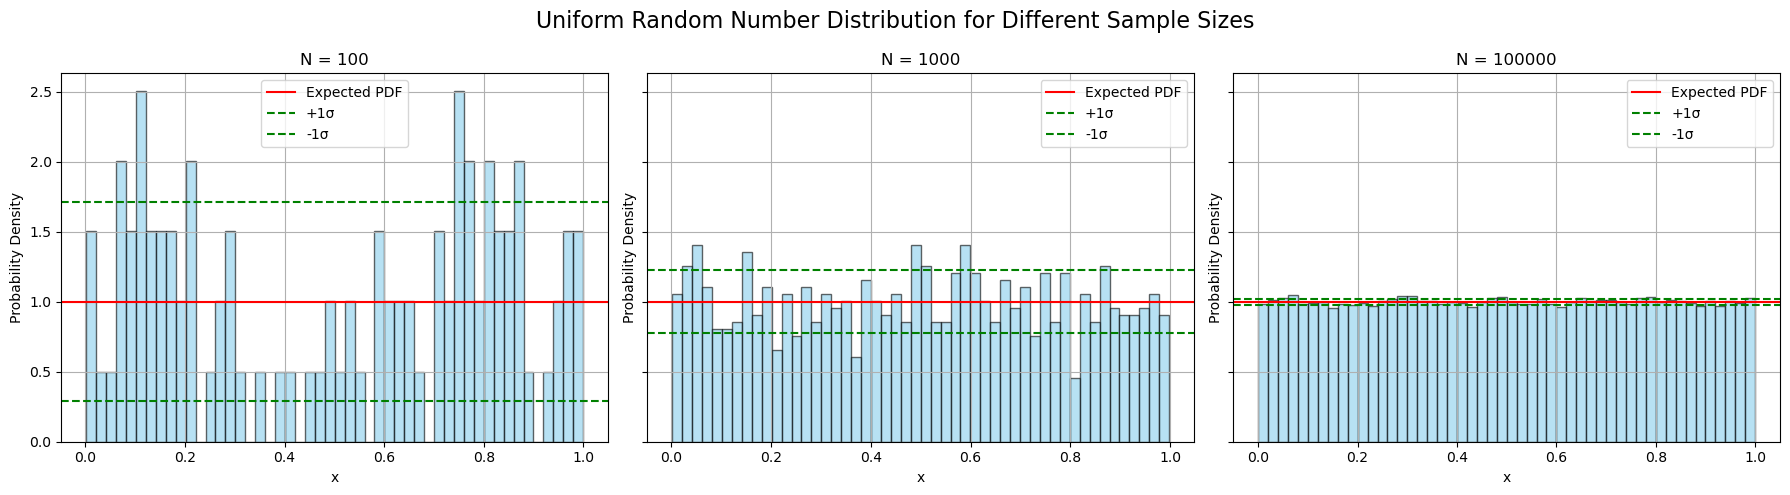

In [5]:
# Produding a figure with 3 subplots.
fig, ax = plt.subplots(1, 3, figsize = (18, 5), sharey = True)

# Iterating over the list of sample sizes to produce a histogram from each.
for i, N in enumerate(sample_sizes):

    # Generating random numbers in the interval defined by the bounds.
    random_nums = np.random.uniform(a, b, N)

    # Generating histogram.  Here, we consider 50 bins for our histogram, and density = True will normalise it such that it returns the probability density for that bin.
    counts, bins, _ = ax[i].hist(random_nums, bins = n_bins, density = True, alpha = 0.6, color = 'skyblue', edgecolor = 'black')

    # Caluclating the bin width. This will be used to convert the uncertainty in the counts to density uncertainty.
    bin_width = bins[1] - bins[0]

    # Calculating the theoretical probability density of uniformly distributed numbers. 
    mean_density = 1/(b - a)

    # This is the expected counts per bin.
    expected_counts = N/n_bins
    # The uncertainty in the counts follow Poisson statistics. We then convert count uncertainty to density uncertainty using bin width. We use this to find ±1σ.
    sigma_counts = np.sqrt(expected_counts)
    sigma_density = sigma_counts/(N*bin_width)

    # Plotting mean and ±1σ lines on the histogram.
    ax[i].axhline(mean_density, color = 'red', label = 'Expected PDF')
    ax[i].axhline(mean_density + sigma_density, color = 'green', linestyle = '--', label = '+1σ')
    ax[i].axhline(mean_density - sigma_density, color = 'green', linestyle = '--', label = '-1σ')

    # Labeling the axes and giving a title.
    ax[i].set_title(f"N = {N}")
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('Probability Density')
    # Displaying legend and grid.
    ax[i].grid(True)
    ax[i].legend()

# Displaying the main title of the figure.
plt.suptitle('Uniform Random Number Distribution for Different Sample Sizes', fontsize = 16)

plt.tight_layout()
plt.show()

The histograms show the expected convergence towards a uniform probability density as the number of generated random numbers increases. For N = 100, the histogram has large fluctuations because the number of samples per bin is small. Some bins are overrepresented while others are underrepresented, but this is expected from statistical noise. For N = 1000, the distribution is noticeably flatter, although some bin-to-bin variation remains. By N = 100000, the histogram is very close to the expected probability density of 1 across the full interval from 0 to 1. Most of the bin heights lie close to the expected value and within the approximate statistical uncertainty.

The behaviour of the ±1σ is also consistent with the expected statistical scaling. As the number of samples increases, the relative uncertainty decreases approximately as 1/√N. 

This confirms that `numpy.random.uniform()` produces random numbers that are consistent with a uniform distribution over the chosen interval. The improvement with increasing sample size is also consistent with the expected reduction in relative statistical uncertainty as the sample size increases.

### 2.2 Three-Dimensional Random Points and Spectral Issues

The next test is to generate random points in three dimensions using `numpy.random.uniform()`. For a good random number generator, the points should fill the unit cube uniformly, with no obvious planes, bands, or repeating structures.This is then compared with the RANDSSP generator supplied in the project material. RANDSSP is expected to show spectral issues, where the generated points are not truly independent in three dimensions and instead appear arranged in visible planes or bands. This provides a visual test of the quality of the random number generator. 

The same number of points is generated for both methods so that the comparison is fair. Each coordinate is generated over the interval from 0 to 1, so the points should occupy the unit cube.

In [6]:
# Parameters. We take 5000 random numbers between 0 and 1 for each axes.
a = 0
b = 1
N = 5000

The RANDSSP function below is the poor random number generator supplied for comparison. It is a linear congruential generator, which can produce correlations between successive random numbers. When consecutive outputs are grouped into three-dimensional points, these correlations can become visible as spectral artefacts. Note that this function is defined exactly as given in the project material.

In [7]:
# Defining the RANDSSP generator function as given in the project material.
def randssp(p, q):

    try: x
    except NameError:
        m = pow(2, 31)
        a = pow(2, 16) + 3
        c = 0
        x = 123456789
    
    try: p
    except NameError:
        p = 1
    try: q
    except NameError:
        q = p
    
    r = np.zeros([p,q])

    for l in range (0, q):
        for k in range (0, p):
            x = np.mod(a*x + c, m)
            r[k, l] = x/m
    
    return r

Two sets of three-dimensional points are now generated. The first set uses `numpy.random.uniform()`, while the second uses RANDSSP. In both cases, the random numbers are grouped into x, y, and z coordinates.

In [8]:
# This code is to generate a 3D interactive scatter plot to confirm there are no spectral issues using numpy.random.uniform() and compare with RANDSSP.
# Generating 5000 random numbers along x, y, and z.
points = np.random.uniform(a, b, (N, 3))
x1, y1, z1 = points[:,0], points[:,1], points[:,2]

# Generating RANDSSP points along the 3 axes.
spectra = randssp(3, N)
x2 = spectra[0, :]
y2 = spectra[1, :]
z2 = spectra[2, :]

# Defining colour maps based on x + y + z values.
c1 = x1 + y1 + z1
c2 = x2 + y2 + z2

The two point clouds are plotted side by side using the same axis limits and viewing angle. This makes any structure in the generated points easier to compare visually.

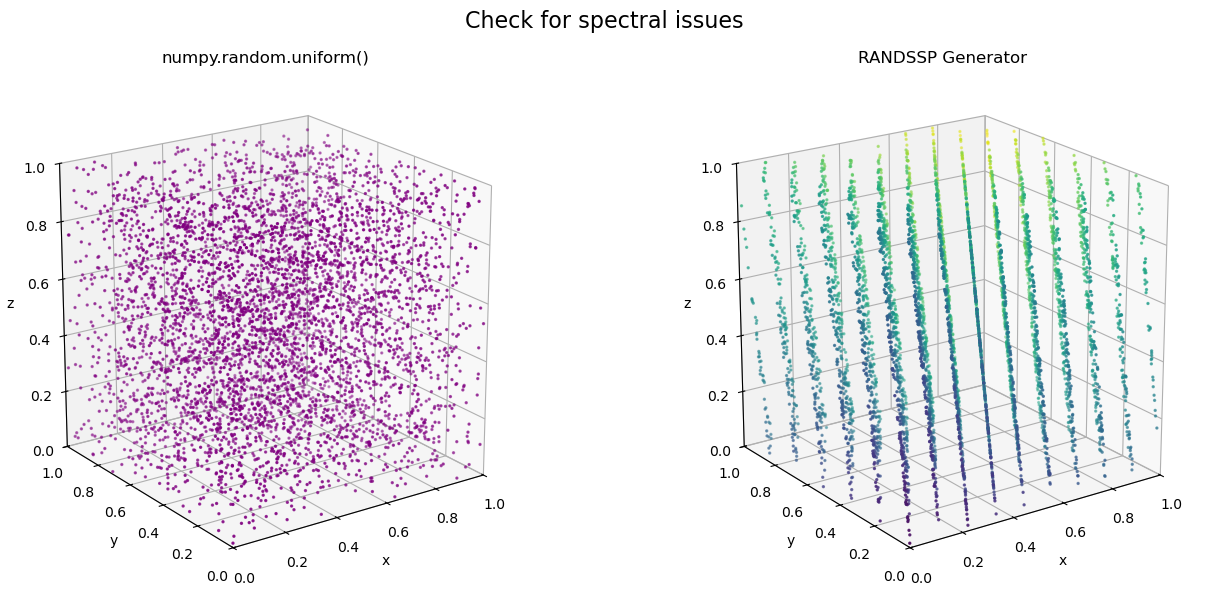

In [9]:
# Creating figure with the plots from the 2 methods side-by-side.
fig = plt.figure(figsize = (14, 6))
ax1 = fig.add_subplot(1, 2, 1, projection = '3d')
ax2 = fig.add_subplot(1, 2, 2, projection = '3d')

# Iterating over both the subplots.
for ax in [ax1, ax2]:

    # Setting the initial viewing angle to show the spectral issues with RANDSSP.
    ax.view_init(elev = 20, azim = -125)

    # Setting the same aspect ratio for both.
    ax.set_box_aspect((0.5, 0.5, 0.5))

    # Setting the same limits for the axes (from 0 to 1).
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.set_zlim(0,1)

    # Labelling the axes.
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

# Plotting the distribution from numpy.random.uniform.
ax1.scatter(x1, y1, z1, s = 2, color = 'purple')
ax1.set_title('numpy.random.uniform()')

# Plotting the distribution from RANDSSP.
ax2.scatter(x2, y2, z2, s = 2, c = c2, cmap = 'viridis')
ax2.set_title('RANDSSP Generator')

# Giving the main title.
plt.suptitle('Check for spectral issues', fontsize = 16)

plt.tight_layout()
plt.show()

The points generated using `numpy.random.uniform()` fill the unit cube without any obvious large-scale structure. There are no visible planes, bands, or repeated patterns, which suggests that the generator is suitable for the Monte Carlo simulations in this project.

In contrast, the RANDSSP generator shows clear spectral artefacts. The points do not fill the volume smoothly, but instead appear arranged into visible bands or planes. This indicates correlations between the generated random numbers, meaning RANDSSP is not suitable for this simulation.

As an additional check, the three-dimensional points generated using `numpy.random.uniform()` are projected onto the three coordinate planes: x-y, x-z, and y-z. If the random numbers are independent and uniformly distributed in three dimensions, then each two-dimensional projection should also appear uniformly filled. This provides a clearer visual check for any correlations between pairs of coordinates. Any strong spectral issue would appear as visible lines, bands, clusters, or empty regions in one or more of these projections.

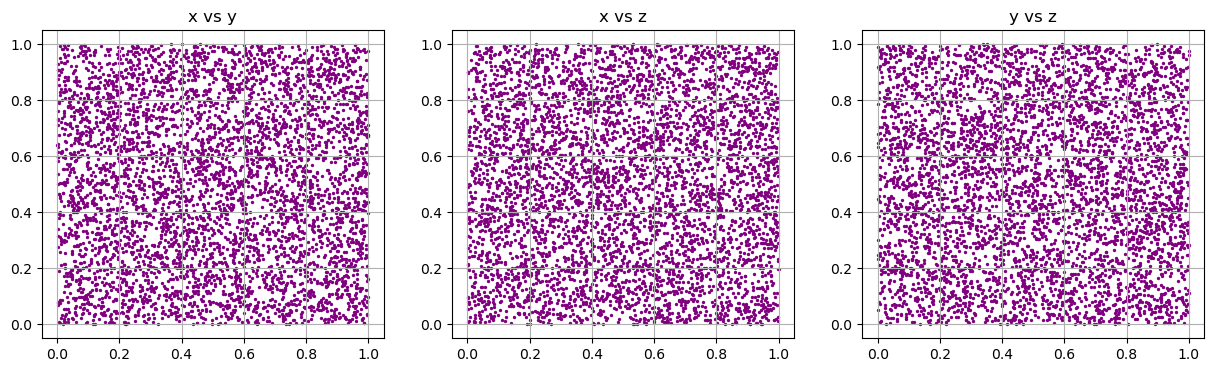

In [10]:
# 2D projections. An extra way to confirm that the distribution is uniform along each plane.
fig = plt.figure(figsize = (15,4))

# Defining a list of subplot titles to iterate over.
titles = ['x vs y',
          'x vs z',
          'y vs z']

# Producing the scatter plot along each plane.
ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(x1, y1, s = 2, color = 'purple')

ax2 = fig.add_subplot(1, 3, 2)
ax2.scatter(x1, z1, s = 2, color = 'purple')

ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(y1, z1, s = 2, color = 'purple')

# Defining the list of subplots to iterate over.
axes = [ax1, ax2, ax3]

# Looping over the 3 subplots and their titles at the same time.
for ax, title in zip(axes, titles):

    # Giving a title to the subplots and displaying gridlines.
    ax.set_title(title)
    ax.grid(True)  
    
plt.show()

The two-dimensional projections show that the points are spread uniformly across each coordinate plane. There are no obvious bands, repeated structures, or preferred directions in the x-y, x-z, or y-z plots.

This supports the conclusion from the three-dimensional scatter plot that `numpy.random.uniform()` does not show visible spectral issues for this sample size. The generated coordinates therefore appear suitable for use in the later Monte Carlo neutron transport simulation.

## 3. Exponential Sampling and Absorption Attenuation

The next step is to create a random number generator that produces path lengths following an exponential distribution. This is needed because the distance travelled by a neutron before an interaction is exponentially distributed, with a characteristic length scale given by the mean free path.

In this section, scattering is ignored so that the only possible interaction is absorption. The relevant attenuation length is therefore calculated using the macroscopic absorption cross-section only. Although the project brief specifically asks for the water attenuation length to be checked, the same calculation is also carried out for lead and graphite for comparison.

### 3.1 Calculating the Absorption Mean Free Path

We start off by defining the parameters as given in the project brief, and also in the table in the Material Data section.

In [11]:
# Constants for [water, lead, graphite]
NA = 6.022e23                                        # Avogadro's Number
rho = [1.00, 11.35, 1.67]                            # Density in g/cm^3
M = [18.0153, 207.2, 12.011]                         # Molar masses in g/mol
sigma_a = [0.6652e-24, 0.158e-24, 0.0045e-24]        # Absorption cross sections in cm^2

The microscopic absorption cross-sections from the project brief are first converted from barns to cm², using 1 barn = 10^-24 cm². The number density of nuclei in each material is calculated from the density and molar mass:

\begin{equation}
n = \frac{\rho N_A}{M}.
\end{equation}

The macroscopic absorption cross-section is then

\begin{equation}
\Sigma_a = n \sigma_a,
\end{equation}

and the absorption mean free path is

\begin{equation}
\lambda_a = \frac{1}{\Sigma_a}.
\end{equation}

This calculation is done in the code below.

In [12]:
# Storage array for the calculated mean free path lengths for the 3 materials.
lambda_value = []
# Calculating the mean free path length from the constants.
for i,j,k in zip(rho, M, sigma_a):

    n = (i*NA)/j                    # Number density in cm^-3
    lambda_value.append(1/(k*n))    # Mean free path length in cm  

materials = ['water', 'lead', 'graphite']
# Displaying the calculated absorption mean free paths
for material, lamb in zip(materials, lambda_value):
    print(f"Absorption mean free path in {material}: {lamb:.2f} cm")

Absorption mean free path in water: 44.97 cm
Absorption mean free path in lead: 191.87 cm
Absorption mean free path in graphite: 2654.05 cm


The calculated absorption mean free path for water is approximately 45 cm, which agrees with the expected characteristic attenuation length stated in the project brief. This confirms that the material data have been converted correctly from microscopic cross-section to macroscopic attenuation length.

The corresponding absorption mean free paths for lead and graphite are much larger. This means that, in an absorption-only model, thermal neutrons are much less likely to be absorbed over short distances in these materials than in water. These calculated values are used as the input mean free paths for the exponential sampling tests in the next section.

### 3.2 Exponential Random Sampling

The distance travelled by a neutron before absorption is sampled from an exponential distribution. If the mean free path is λ, the probability density decreases as:

\begin{equation}
p(x) \propto e^{-x/\lambda}
\end{equation}

To generate samples from this distribution, inverse transform sampling is used. Starting from a uniformly distributed random number u between 0 and 1, the exponentially distributed distance is calculated using:

\begin{equation}
x = -\lambda \ln(u)
\end{equation}

Here, λ is the absorption mean free path calculated previously. Since u and 1-u are both uniformly distributed over the same interval, either form gives the same exponential distribution.

In [13]:
# Defining the function to generate exponential path lengths.
def sample_exponential(mean_free_path, N):
    
    # Generates random numbers uniformly distributed between 0 and 1.
    u = np.random.uniform(0, 1, N)
    # We use the uniformly distributed random numbers to generate random path lengths distributed exponentially. Note that u and 1-u are equivalent.
    x = -mean_free_path * np.log(u)
    return x

This will be the function that will be called in the next section.
### 3.3 Single-Trial Exponential Distribution

The exponential sampling test is repeated using a large number of sampled path lengths so that the resulting histogram gives a smooth approximation to the underlying probability density. Here, 10000 sampled neutron path lengths are generated per simulation. This is large enough to produce a clear exponential distribution while still being consistent with the sample sizes used later in the neutron transport simulation.

The histogram is divided into 50 bins, and later the process is repeated over 100 independent trials to estimate the fitted attenuation length and its uncertainty more reliably.

In [14]:
# Constants for exponential sampling and histogram configuration. We consider 10000 neutrons per simulation and 100 simulations. 
N = 10000
n_bins = 50
n_trials = 100

A single set of exponentially distributed path lengths is first generated for each material using the absorption mean free paths calculated earlier. The sampled path lengths are binned into a normalised histogram, so the y-axis represents probability density rather than raw counts. For an exponential distribution, taking the logarithm of the probability density gives a straight-line relation:

\begin{equation}
\ln(p(x)) = -\frac{x}{\lambda} + C
\end{equation}

where λ is the attenuation length and C is a constant. Therefore, a straight-line fit to the logarithm of the histogram density can be used to reconstruct the exponential decay curve. Empty bins are removed before fitting because their logarithm is undefined. The histogram range is set from 0 to 8λ for each material. This keeps the plotted range proportional to the relevant attenuation length, making the three materials comparable despite having very different λ values. For an exponential distribution, the probability of sampling a path length greater than 8λ is very small.

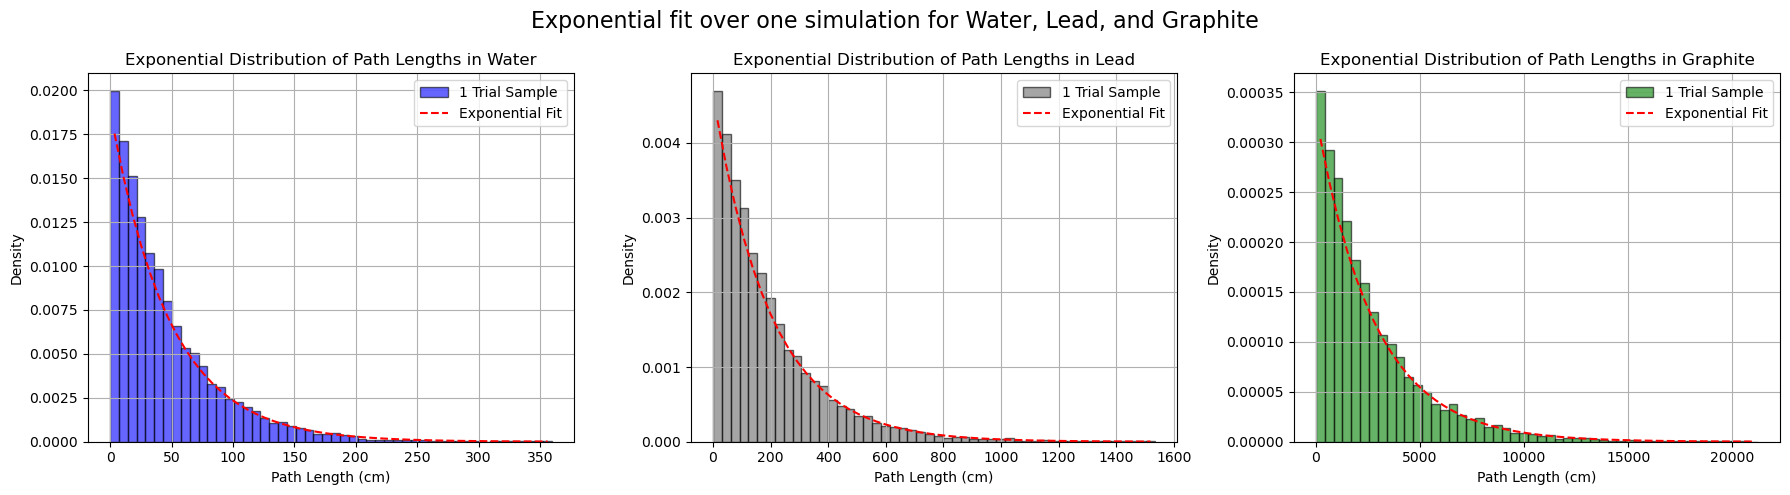

In [15]:
# Defining the list for names of materials and colors for the plot.
materials = ['Water', 'Lead', 'Graphite']
colors = ['blue', 'dimgray', 'green']
      
# Creating the figure with 3 subplots for plotting. 
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
plt.suptitle('Exponential fit over one simulation for Water, Lead, and Graphite', fontsize = 16)

# Looping over the index, material, mean free path, and color at the same time to perform Monte Carlo for each material and plot it in the same loop.
for i, (mat, lam, color) in enumerate(zip(materials, lambda_value, colors)):

    # Now we generate one trial sample for showing the exponential fit on a single histogram.
    exp_sample = sample_exponential(lam, N)
    # The range of the histogram is set to 8 times the mean free path of the material.
    exp_counts, exp_edges = np.histogram(exp_sample, bins = n_bins, range = (0, 8*lam), density = True)

    # Defining the bin centers to use as the x axis in plotting.
    exp_centers = 0.5 * (exp_edges[:-1] + exp_edges[1:])
    
    # Mask for filtering out empty bins.
    exp_nonzero = exp_counts > 0
    # We fit the logarithm of the nonzero histogram densities using polyfit.
    exp_linear_fit = np.polyfit(exp_centers[exp_nonzero], np.log(exp_counts[exp_nonzero]), 1)
    # The exponential curve is reconstructed from the linear fit in log-space using polyval for plotting.
    exp_curve = np.exp(np.polyval(exp_linear_fit, exp_centers))

    # Plotting the single sample histogram and exponential fit in the top row.
    ax[i].hist(exp_sample, bins = n_bins, range = (0, 8*lam), density = True, alpha = 0.6, color = color, label = '1 Trial Sample', edgecolor = 'black')
    ax[i].plot(exp_centers, exp_curve, 'r--', label = 'Exponential Fit')
    
    # Giving a title and labeling the axes.
    ax[i].set_title(f"Exponential Distribution of Path Lengths in {mat}")
    ax[i].set_xlabel('Path Length (cm)')
    ax[i].set_ylabel('Density')
    # Displaying legend and grid.
    ax[i].legend()
    ax[i].grid(True)

plt.tight_layout()
plt.show()

The histograms show the expected exponential behaviour for all three materials. In each case, the probability density is largest at short path lengths and decreases rapidly as the path length increases. This is consistent with the physical interpretation that absorption is most likely after shorter distances, while very long path lengths are progressively less probable.

The fitted exponential curves follow the sampled histograms closely, showing that the inverse transform sampling method successfully generates path lengths with the required exponential distribution. The different horizontal scales arise from the different absorption mean free paths of the materials. 

This single-trial plot is mainly a visual check. A more reliable estimate of the attenuation length and its uncertainty is obtained by repeating the sampling and fitting over many independent trials.

### 3.4 Fitting the Attenuation Length

To obtain a more reliable estimate of the attenuation length, the exponential sampling is repeated over 100 independent trials for each material. For each trial, 50000 path lengths are generated and binned into a histogram. The raw bin counts are stored, and the mean and standard deviation of the counts are calculated across the 100 trials.

For an exponential distribution, the expected number of counts in each bin decreases approximately as:

\begin{equation}
N(x) = N_0 e^{-x/\lambda}
\end{equation}

Taking the natural logarithm gives a linear relationship:

\begin{equation}
\ln(N(x)) = \ln(N_0) - \frac{x}{\lambda}
\end{equation}

Therefore, the attenuation length can be found from the gradient of a straight-line fit to ln(counts) against path length. If the fitted gradient is m, then:

\begin{equation}
\lambda = -\frac{1}{m}
\end{equation}

The standard deviation of the bin counts across the repeated trials is propagated into log-space using:

\begin{equation}
\sigma_{\ln N} = \frac{\sigma_N}{N}
\end{equation}

These uncertainties are used as weights in `numpy.polyfit`, so bins with smaller uncertainty contribute more strongly to the fitted line. Bins with zero mean count or zero standard deviation are removed before fitting because the logarithm and the weighting would otherwise be undefined.

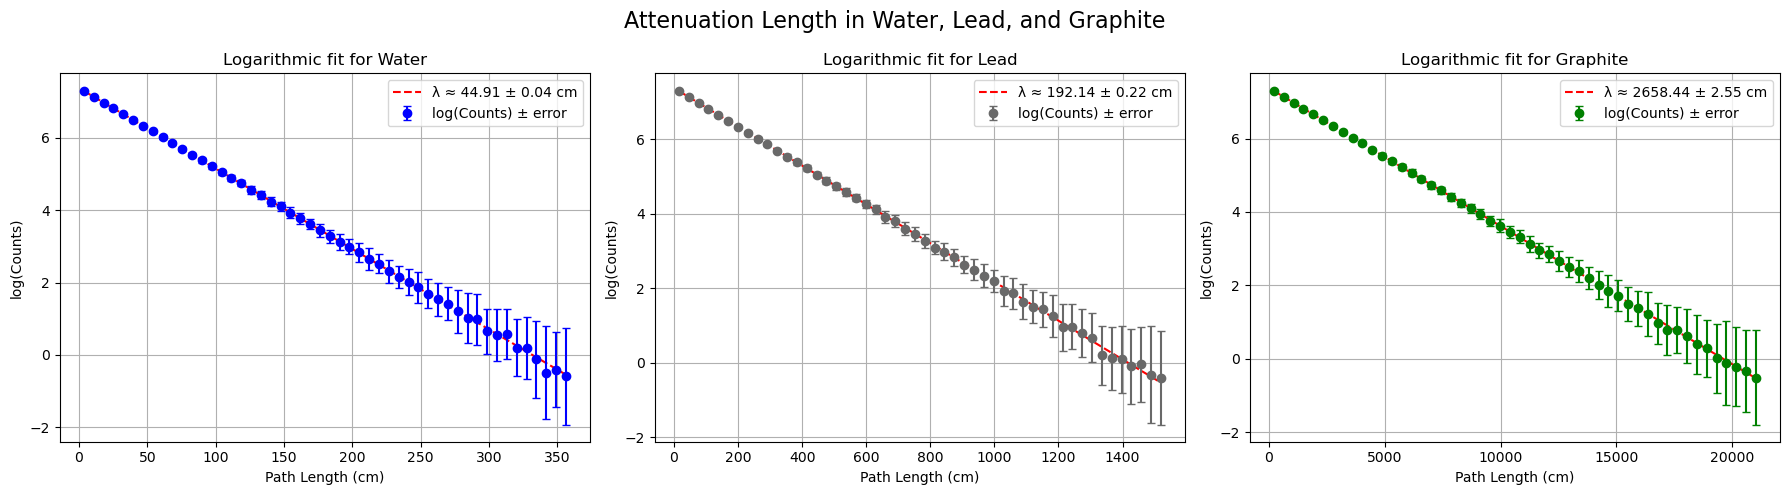

In [16]:
# Creating the figure with 3 subplots for plotting. 
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
plt.suptitle('Attenuation Length in Water, Lead, and Graphite', fontsize = 16)

# Looping over the index, material, mean free path, and color at the same time to perform Monte Carlo for each material and plot it in the same loop.
for i, (mat, lam, color) in enumerate(zip(materials, lambda_value, colors)):
    
    # Storage array for counts from each generated histogram as we will be performing 100 Monte Carlo simulations. This is a 2D array containing the counts of each bin (y axis) of each histogram (x axis).
    counts_MC = np.zeros((n_trials, n_bins))

    # Perform 100 trials of exponential sampling
    for j in range(n_trials):
        
        x_sample = sample_exponential(lam, N)
        # Histogram the sampled path lengths into raw bin counts.
        counts, bin_edges = np.histogram(x_sample, bins = n_bins, range = (0, 8*lam))
        
        # Defining histogram bin centers for using as x axis in plotting.
        bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

        # Storing the counts of the histogram generated from this simulation.
        counts_MC[j] = counts
    
    # Computing mean and standard deviation of counts.
    mean_counts = np.mean(counts_MC, axis = 0)
    std_counts = np.std(counts_MC, axis = 0)
    
    # Removing zero counts to make it safe for log.
    mask =  (mean_counts > 0) & (std_counts > 0)
    # Converting the standard deviation to standard deviation in log through error propagation.
    log_mean = np.log(mean_counts[mask])
    log_std = std_counts[mask]/mean_counts[mask]
    
    # Weighted log fit after averaging 100 simulations.
    x_fit = bin_centers[mask]
    y_fit = log_mean
    coeffs, cov = np.polyfit(x_fit, y_fit, 1, w = 1/log_std, cov = True)
    # lambda_fit calculated here from the slope is the lambda calculated from fitting over the averaged histogram.
    slope = coeffs[0]
    # The error in the slope is found using the covariance matrix.
    slope_err = np.sqrt(cov[0, 0])
    lambda_fit = -1/slope
    # This is the error found through error propagation.
    lambda_fit_err = slope_err/slope**2

    # Plotting log of mean counts with error bars and fit.
    ax[i].plot(x_fit, np.polyval(coeffs, x_fit), 'r--', label = f"λ ≈ {lambda_fit:.2f} ± {lambda_fit_err:.2f} cm")
    ax[i].errorbar(bin_centers[mask], log_mean, yerr = log_std, fmt = 'o', color = color, capsize = 3, label = 'log(Counts) ± error')

    # Giving a title and labeling the axes.
    ax[i].set_title(f"Logarithmic fit for {mat}")
    ax[i].set_xlabel('Path Length (cm)')
    ax[i].set_ylabel('log(Counts)')
    # Displaying legend and grid.
    ax[i].grid(True)
    ax[i].legend()

plt.tight_layout()
plt.show()

The logarithmic plots show a clear linear relationship between ln(counts) and path length for all three materials. This confirms that the sampled path lengths follow the expected exponential attenuation law. The fitted attenuation lengths(as seen on the plot) agree closely with the absorption mean free paths calculated directly from the material data. In particular, the water value is approximately 45 cm, as expected from the project brief.

The error bars become larger at long path lengths because fewer neutrons reach those distances, so the relative statistical uncertainty in the bin counts increases. This is why the tail of the distribution has visibly larger uncertainties. The weighted fit accounts for this by giving less weight to the noisier low-count bins.

## 4. Isotropic Unit Vectors and Random Steps

The neutron transport simulation requires random scattering directions after each scattering event. For an isotropic scatter, all directions over the surface of a sphere should be equally likely. This means the generated unit vectors must have magnitude 1 and must not show clustering near any particular direction.

### 4.1 Generating Isotropic Unit Vectors

A common mistake when generating random directions is to sample both spherical angles θ and φ uniformly. This does not produce a uniform distribution over the sphere, because points would cluster near the poles. Instead, φ is sampled uniformly from 0 to 2π, while cos(θ) is sampled uniformly from −1 to 1. The spherical polar coordinates are then converted into Cartesian components using:

\begin{equation}
u_x = \sin(\theta)\cos(\phi)
\end{equation}

\begin{equation}
u_y = \sin(\theta)\sin(\phi)
\end{equation}

\begin{equation}
u_z = \cos(\theta)
\end{equation}

This gives unit vectors of the form:

\begin{equation}
\vec{u} = u_x\hat{i} + u_y\hat{j} + u_z\hat{k}
\end{equation}

with:

\begin{equation}
|\vec{u}| = 1
\end{equation}

In [17]:
# This is the function to generate N random isotropic unit vectors on a sphere
def isotropic_unit_vector(N):

    # Defining the azimuthal angle as random numbers between 0 and 2 pi.
    phi = np.random.uniform(0, 2*np.pi, N)

    # For a uniform distribution without clustering, we need random numbers generated between -1 and 1 as values of cos(theta).
    cos_theta = np.random.uniform(-1, 1, N)
    theta = np.arccos(cos_theta)

    # Converting from spherical polar coordinates to Cartesian coordinates.
    ux = np.sin(theta) * np.cos(phi)
    uy = np.sin(theta) * np.sin(phi)
    uz = np.cos(theta)

    # Returning the unit vectors as a numpy array.
    return np.array([ux, uy, uz])

### 4.2 Visual Test of Isotropic Directions

To check that the generated unit vectors are isotropically distributed, 1000 vectors are plotted in three dimensions. Since each vector has magnitude 1, the points should lie on the surface of a sphere. If the sampling is isotropic, the sphere should appear uniformly covered without visible clustering near the poles or along preferred directions.

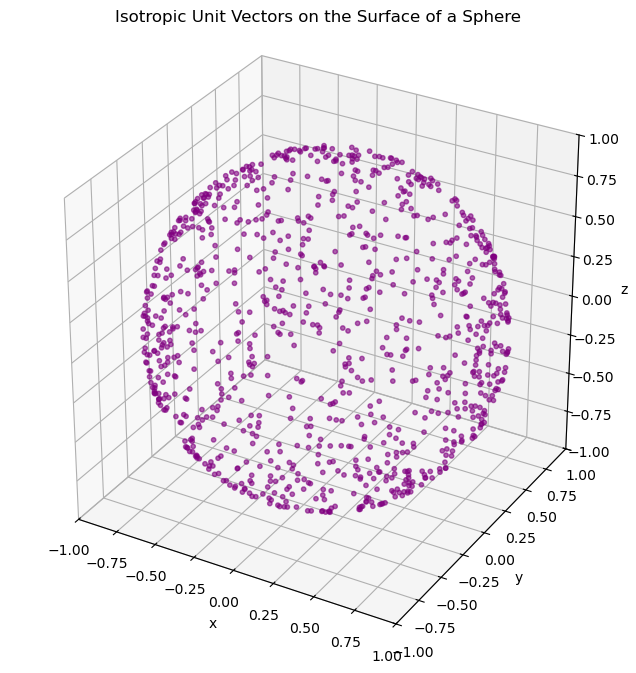

In [18]:
# Generating 1000 isotropic unit vectors by calling the function.
direction = isotropic_unit_vector(1000)

# Extracting x, y and z components of the vectors.
x, y, z = direction[0], direction[1], direction[2]


# Creating a 3D matplotlib figure.
fig = plt.figure(figsize = (8, 8))
ax = fig.add_subplot(111, projection = '3d')

# Producing the 3D scatter plot.
ax.scatter(x, y, z, s = 10, alpha = 0.6, color = 'purple')

# Labelling the axes and giving a title.
ax.set_title('Isotropic Unit Vectors on the Surface of a Sphere')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

# Fixing the axis limits so the sphere is not distorted.
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_zlim([-1, 1])

# Ensuring equal aspect ratio on all axes.
ax.set_box_aspect([1, 1, 1])

# Displaying grid.
ax.grid(True)

plt.show()

The generated points lie on the surface of a sphere, as expected for unit vectors. The distribution appears approximately uniform over the sphere, with no clear clustering near the poles and no preferred direction. This confirms that sampling φ uniformly from 0 to 2π and cos(θ) uniformly from −1 to 1 produces isotropic unit vectors. This function can therefore be used later to assign random scattering directions to neutrons after scattering events.

### 4.3 Generating Isotropic Neutron Steps

The isotropic unit-vector function can now be combined with exponential path-length sampling to generate complete neutron steps. Each step has two parts: a randomly sampled length and a randomly sampled direction. The step length is sampled from the exponential distribution:

\begin{equation}
s = -\lambda \ln(u)
\end{equation}

where λ is the mean free path and u is a uniformly distributed random number between 0 and 1. The direction of the step is then chosen isotropically using the unit-vector function defined previously. The full step vector is therefore:

\begin{equation}
\vec{s} = s\vec{u}
\end{equation}

where s is the exponentially distributed step length and ū is the isotropic unit vector. This gives a random displacement in three dimensions with the correct step-length distribution and no preferred direction. The function to do this for N neutrons is defined below.

In [19]:
# Defining the function for generating a step for N neutrons.
def neutron_sample_step(N, lambda_value):

    # The length of the step is defined according to an exponential distribution.
    u = np.random.uniform(0, 1, N)
    step_length = -lambda_value * np.log(u)

    # The function for isotropic unit vectors is used to define a random direction for the step.
    direction = isotropic_unit_vector(N)

    # Scaling each component of the step with the exponentially distributed step length.
    return step_length * direction, step_length

A sample of 5000 neutron steps is generated using a mean free path of λ = 45 cm, corresponding approximately to the absorption-only attenuation length for water. The resulting step vectors are plotted in three dimensions to check that the directions are isotropic. The colour gradient in the 3D plot represents the step length. This is included to make the distribution easier to interpret in the static notebook output: shorter steps should appear concentrated near the origin, while the rarer longer steps extend further away. A histogram of the sampled step lengths is also plotted and compared with the expected exponential probability density:

\begin{equation}
p(s) = \frac{1}{\lambda}e^{-s/\lambda}
\end{equation}

This checks that the generated steps have both the correct angular distribution and the correct exponential length distribution.

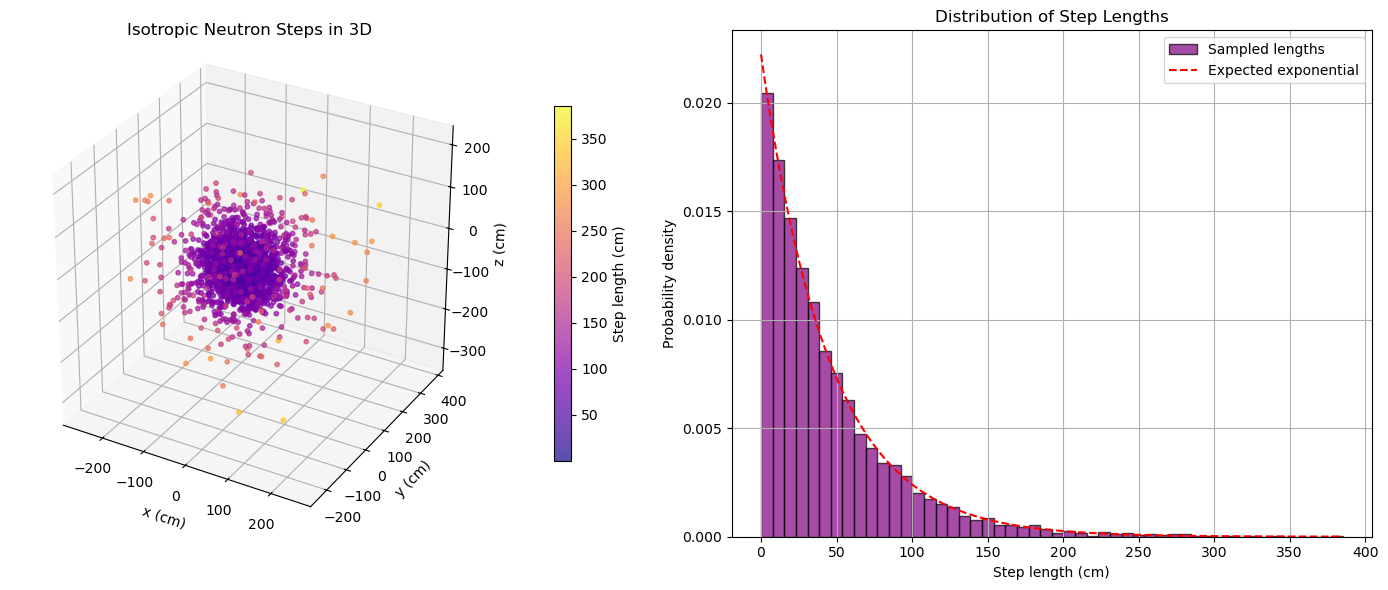

In [20]:
# Defining the mean free path.
lambda_test = 45

# Generating 1000 neutron steps.
sample_step, s = neutron_sample_step(5000, lambda_test)
# Extracting x, y and z components of the steps.
x, y, z = sample_step[0], sample_step[1], sample_step[2]

# Creating a figure with 2 subplots.
fig = plt.figure(figsize = (14, 6))

# The first subplot is of the 3D distribution.
ax1 = fig.add_subplot(121, projection = '3d')
# The colour gradient represents the distance of the step from the origin.
scatter = ax1.scatter(x, y, z, c = s, cmap = 'plasma', s = 10, alpha = 0.7)
# Adding a colour bar to show the step length represented by the colour gradient
cbar = fig.colorbar(scatter, ax=ax1, shrink=0.7, pad=0.1)
cbar.set_label('Step length (cm)')

# Labelling the axes and giving a title.
ax1.set_title('Isotropic Neutron Steps in 3D')
ax1.set_xlabel('x (cm)')
ax1.set_ylabel('y (cm)')
ax1.set_zlabel('z (cm)')

# Ensuring equal scaling on all axes.
ax1.set_box_aspect([1, 1, 1])

# Adding a subplot to demonstrate that it is exponentially sampled.
ax2 = fig.add_subplot(122)
# Producing histogram of sampled step lengths.
ax2.hist(s, bins = 50, density = True, alpha = 0.7, color = 'purple', edgecolor = 'black', label = 'Sampled lengths')

# Defining an array of step lengths for plotting the theoretical exponential distribution.
x_fit = np.linspace(0, np.max(s), 500)

# Plotting the expected exponential distribution.
ax2.plot(x_fit, (1/lambda_test) * np.exp(-x_fit/lambda_test), 'r--', label = 'Expected exponential')

# Giving a title and labelling the axes.
ax2.set_title('Distribution of Step Lengths')
ax2.set_xlabel('Step length (cm)')
ax2.set_ylabel('Probability density')
# Displaying legend and grid.
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

The three-dimensional scatter plot shows that the generated neutron steps are distributed in all directions around the origin, with no obvious preferred direction. This confirms that the isotropic unit-vector function is being correctly used to generate random step directions.

The step-length histogram follows the expected exponential shape. Most steps are short, while longer steps occur with decreasing probability. The agreement between the histogram and the theoretical exponential curve confirms that the step lengths are being sampled correctly.

This function therefore provides the basic random displacement needed for the neutron transport simulation. Each neutron can now be moved by an exponentially distributed distance in an isotropically sampled direction.

## 5. Determining Material Properties

The previous sections developed and tested the random number tools needed for the Monte Carlo simulation: uniform random number generation, exponential path-length sampling, isotropic unit vectors, and isotropic neutron steps. These components can now be combined to simulate thermal neutrons travelling through shielding slabs.

The first step is to calculate the material properties needed by the transport model. For each material, the microscopic absorption and scattering cross-sections are converted into macroscopic cross-sections. These determine the probabilities of absorption and scattering per unit length, and hence the total mean free path used in the random-walk simulation. 

### 5.1 Material Constants

The material data from the project brief are defined below for water, lead, and graphite. The microscopic cross-sections are converted from barns to cm² using the conversion factor:

\begin{equation}
1 \ \mathrm{barn} = 10^{-24} \ \mathrm{cm}^{2}
\end{equation}

Both absorption and scattering cross-sections are now included, because the full neutron transport simulation must account for both processes.

In [21]:
# Constants
NA = 6.022e23  # Avogadro number in mol^-1
# This is used to convert from barns to cm^2
barn = 1e-24   # in cm^2

# Defining the list of materials considered.
materials = ["Water", "Lead", "Graphite"]

# Data in order of [water, lead, graphite].
rho = np.array([1.00, 11.35, 1.67])          # in g/cm^3
M = np.array([18.0153, 207.2, 12.011])       # in g/mol

sigma_a = np.array([0.6652, 0.158, 0.0045]) * barn   # in cm^2 (Absorption)
sigma_s = np.array([103.0, 11.221, 4.74]) * barn     # in cm^2 (Scattering)

### 5.2 Macroscopic Cross-Sections and Total Mean Free Path

The number density of nuclei in each material is calculated from the density, molar mass, and Avogadro's number like before. The microscopic cross-sections describe the interaction probability for a single nucleus. For the bulk material, these are converted into macroscopic cross-sections using:

\begin{equation}
\Sigma_a = n\sigma_a
\end{equation}

\begin{equation}
\Sigma_s = n\sigma_s
\end{equation}

The total macroscopic cross-section is the sum of the absorption and scattering contributions:

\begin{equation}
\Sigma_t = \Sigma_a + \Sigma_s
\end{equation}

The total mean free path is then:

\begin{equation}
\lambda = \frac{1}{\Sigma_t}
\end{equation}

This total mean free path is different from the absorption-only attenuation length calculated earlier. Here, scattering is included, so λ represents the average distance travelled before either absorption or scattering occurs.

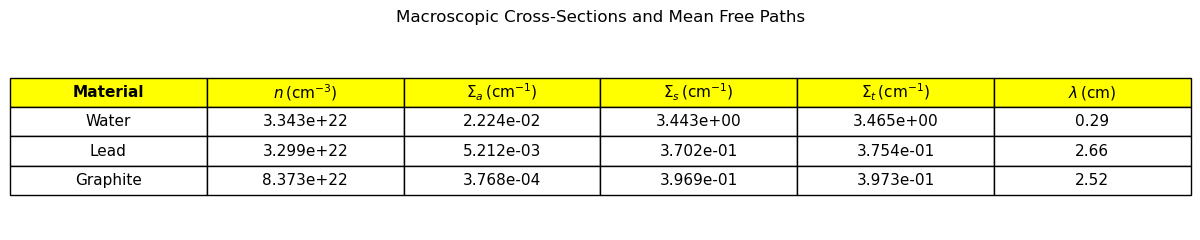

In [22]:
# Calculating number density.
n = rho * NA / M   # in cm^-3

# Calculating the macroscopic cross-sections in cm^-1.
Sigma_a = n * sigma_a        # Absorption
Sigma_s = n * sigma_s        # Scattering
Sigma_t = Sigma_a + Sigma_s  # Total

# Calculating the total mean free path in cm.
lambda_t = 1 / Sigma_t

# Defining an empty list to store table data.
table = []

# Looping over each material to produce a row of data for the material.
for i in range(len(materials)):
    
    # Appending a row in order of [material, n, Σ_a, Σ_s, Σ_t, λ].
    table.append([
        materials[i],
        f"{n[i]:.3e}",
        f"{Sigma_a[i]:.3e}",
        f"{Sigma_s[i]:.3e}",
        f"{Sigma_t[i]:.3e}",
        f"{lambda_t[i]:.2f}"
    ])

# Defining the header row using LaTeX symbols.
headers = [
    'Material',
    r'$n \, (\mathrm{cm}^{-3})$',
    r'$\Sigma_a \, (\mathrm{cm}^{-1})$',
    r'$\Sigma_s \, (\mathrm{cm}^{-1})$',
    r'$\Sigma_t \, (\mathrm{cm}^{-1})$',
    r'$\lambda \, (\mathrm{cm})$'
]

# Creating a matplotlib figure for the table.
fig, ax = plt.subplots(figsize = (12, 2.5))

# Turning off axes since we only want the table.
ax.axis('off')

# Creating the table.
table_plot = ax.table(cellText = table, colLabels = headers, cellLoc = 'center', loc = 'center')

# Formatting the table.
table_plot.auto_set_font_size(False)
table_plot.set_fontsize(11)
table_plot.scale(1.2, 1.8)

# Making the header row bold and shaded.
for (row, col), cell in table_plot.get_celld().items():

    # Header row.
    if row == 0:
        cell.set_text_props(weight = 'bold')
        cell.set_facecolor('yellow')

# Giving a title.
plt.title('Macroscopic Cross-Sections and Mean Free Paths', pad = 15)

plt.tight_layout()
plt.show()

The calculated values show that scattering dominates over absorption for all three materials, since Σs is much larger than Σa in each case. This means that a neutron is much more likely to scatter than be absorbed at each interaction.

The total mean free paths are much shorter than the absorption-only mean free paths calculated earlier. For example, water had an absorption-only mean free path of about 45 cm, but its total mean free path here is about 0.29 cm once scattering is included. This is because thermal neutrons scatter very frequently in water. Lead and graphite have longer total mean free paths than water, but they are still only a few centimetres. These values will be used in the random-walk simulation to determine the distance travelled before each interaction.

## 6. Visualising Neutron Random Walks

The next stage is to simulate the path of individual neutrons through a slab of material. The slab is placed between x = 0 and x = L, and each neutron enters from the left-hand side at x = 0 travelling initially in the +x direction.

At each step, the distance to the next interaction is sampled from an exponential distribution using the total mean free path λ, where λ includes both absorption and scattering. Once the neutron reaches the next interaction point, three outcomes are possible:

- if x < 0, the neutron has escaped from the left side and is counted as reflected;
- if x > L, the neutron has escaped from the right side and is counted as transmitted;
- if 0 < x < L, the neutron interacts inside the slab and is either absorbed or scattered.

The probability that an interaction is absorption rather than scattering is determined by the relative size of the macroscopic absorption cross-section:

\begin{equation}
P_{\mathrm{abs}} = \frac{\Sigma_a}{\Sigma_t}
\end{equation}

If the neutron is not absorbed, it is scattered and assigned a new isotropic direction. The random walk then continues until the neutron is absorbed, reflected, or transmitted.

### 6.1 Sampling the Distance to the Next Interaction

The distance to the next interaction is sampled from an exponential distribution using the total mean free path λ. This is the same inverse transform sampling method used earlier, but here λ is the total mean free path rather than the absorption-only attenuation length.

In [23]:
# Function to sample a single exponentially distributed step length
def sample_step_length(lambda_value):
    
    # Generating a uniformly distributed random number
    u = np.random.uniform(0, 1)
    
    # Converting it into an exponentially distributed path length
    return -lambda_value * np.log(u)

### 6.2 Simulating a Single Neutron Path

The function below simulates the random walk of one neutron through the slab. A `while` loop is used because the number of steps is not known in advance. The neutron continues moving until it reaches one of the final outcomes: absorption, reflection, or transmission.

The neutron starts at x = 0 and initially travels in the +x direction (normal incidence). After each sampled step, the new x-position is checked to determine whether the neutron has escaped from the slab. If it remains inside the slab, the interaction is tested as either absorption or scattering. If scattering occurs, a new isotropic direction is generated and the walk continues.

In [24]:
# Defiining the function to simulate the random walk of a single neutron through a slab.
def simulate_neutron_path(lambda_value, Sigma_a, Sigma_s, slab_thickness):

    # Calculating the total macroscopic cross-section and absorption probability.
    Sigma_t = Sigma_a + Sigma_s
    p_absorb = Sigma_a / Sigma_t

    # Setting the initial position at the left edge of the slab.
    position = np.array([0.0, 0.0, 0.0])
    # Initial direction is perpendicular into the slab, along +x.
    direction = np.array([1.0, 0.0, 0.0])
    # Making a copy of position array to store the neutron path.
    path = [position.copy()]

    # The random walk continues until the neutron is absorbed, reflected, or transmitted.
    while True:

        # Sampling the distance to the next interaction.
        step_length = sample_step_length(lambda_value)

        # Updating the neutron position
        new_position = position + step_length * direction

        # Storing the new position
        path.append(new_position.copy())

        # Checking if the neutron has escaped through the left side (reflection).
        if new_position[0] < 0:
            return np.array(path), 'reflected'

        # Checking if the neutron has escaped through the right side (transmission).
        elif new_position[0] > slab_thickness:
            return np.array(path), 'transmitted'

        # If the neutron is still inside the slab, it undergoes an interaction. The interaction is either absorption or scattering.
        if np.random.uniform(0, 1) < p_absorb:
            return np.array(path), 'absorbed'

        # If the neutron is not absorbed, it scatters. Its position is updated and a new isotropic direction is chosen.
        position = new_position
        direction = isotropic_unit_vector(1).flatten()

### 6.3 Material Properties for the Random Walk

The material properties calculated earlier are stored in a dictionary so that the random-walk simulation can be applied to water, lead, and graphite using the same functions. Each material is assigned its macroscopic absorption cross-section, scattering cross-section, total cross-section, total mean free path, and plotting colour.

In [25]:
# We use the data calculated for each material earlier, and construct a dictionary. The color is used to plot the color of the surface of the material for better representation.
material_properties = {
    'Water': {
        'Sigma_a': Sigma_a[0],
        'Sigma_s': Sigma_s[0],
        'Sigma_t': Sigma_t[0],
        'lambda' : lambda_t[0],
        'color'  : 'blue'
    },
    'Lead': {
        'Sigma_a': Sigma_a[1],
        'Sigma_s': Sigma_s[1],
        'Sigma_t': Sigma_t[1],
        'lambda' : lambda_t[1],
        'color'  : 'dimgray'
    },
    'Graphite': {
        'Sigma_a': Sigma_a[2],
        'Sigma_s': Sigma_s[2],
        'Sigma_t': Sigma_t[2],
        'lambda' : lambda_t[2],
        'color'  : 'green'
    }
}

### 6.4 Plotting Neutron Random Walks

A small number of neutron paths are plotted for each material to visualise the random-walk behaviour. The two transparent planes represent the slab boundaries at x = 0 and x = L.

The neutron path is shown as a black line. The starting point is marked separately (green), while the final point is coloured according to the outcome: absorbed(red), reflected(purple), or transmitted(orange). A slab thickness of L = 3 cm is used for this visualisation because it is large enough to show multiple scattering events while still allowing all three outcomes to be seen clearly.

In [26]:
# Defining a function to plot the path for each neutron. The number of neutrons simulated is an argument of this function.
def plot_neutron_paths(material_name, material_data, slab_thickness, ax, n_neutrons = 5):

    # Defining a dictionary of colors for each outcome for better visualisation.
    colors = {
        'absorbed':'red',
        'transmitted':'orange',
        'reflected':'purple'
    }
 
    # Define slab plane extent (how big the plane is in y and z). We set it to 3 times the set slab thickness for a good representation.
    plane_size = slab_thickness * 3
    y = np.linspace(-plane_size, plane_size, 2)
    z = np.linspace(-plane_size, plane_size, 2)
    x = np.linspace(0, slab_thickness, 2)

    Y, Z = np.meshgrid(y, z)
    X0 = np.zeros_like(Y)
    XL = slab_thickness * np.ones_like(Y)

    # Defining boundary planes at x = 0 and x = L.
    ax.plot_surface(X0, Y, Z, alpha = 0.18, color = material_data['color'])
    ax.plot_surface(XL, Y, Z, alpha = 0.18, color = material_data['color'])

    # Adding faint top/bottom/side faces to suggest the slab volume. It is kept faint so that the paths are still visible inside.
    X, Y_side = np.meshgrid(x, y)                # Side
    Z_top = plane_size * np.ones_like(X)         # Top
    Z_bottom = -plane_size * np.ones_like(X)     # Bottom
   
    ax.plot_surface(X, Y_side, Z_top, alpha = 0.06, color = material_data['color'])
    ax.plot_surface(X, Y_side, Z_bottom, alpha = 0.06, color = material_data['color'])

    X, Z_side = np.meshgrid(x, z)
    Y_top = plane_size * np.ones_like(X)
    Y_bottom = -plane_size * np.ones_like(X)
    ax.plot_surface(X, Y_top, Z_side, alpha = 0.06, color = material_data['color'])
    ax.plot_surface(X, Y_bottom, Z_side, alpha = 0.06, color = material_data['color'])

    # Looping over each neutron
    for _ in range(n_neutrons):
        # Calling the function to simulate a single neutron path and its outcome.
        path, outcome = simulate_neutron_path(lambda_value = material_data['lambda'], 
                                              Sigma_a = material_data['Sigma_a'], 
                                              Sigma_s = material_data['Sigma_s'], 
                                              slab_thickness = slab_thickness
                                             )

        # Plotting the path in 3D.
        ax.plot(path[:, 0], path[:, 1], path[:, 2], alpha = 0.8, color = 'black')
        # Representing the starting point of the path with a cyan point.
        ax.scatter(path[0, 0], path[0, 1], path[0, 2], color = 'cyan', s = 20, label = 'Start')
        # Representing the ending point of the path with the color of its outcome.
        ax.scatter(path[-1, 0], path[-1, 1], path[-1, 2], color = colors[outcome], s = 20)

    # Giving a title and labeling the axes
    ax.set_title(f'{material_name}')
    ax.set_xlabel('x (cm)')
    ax.set_ylabel('y (cm)')
    ax.set_zlabel('z (cm)')

And now we can use all these functions to visualise the 3D random walk.

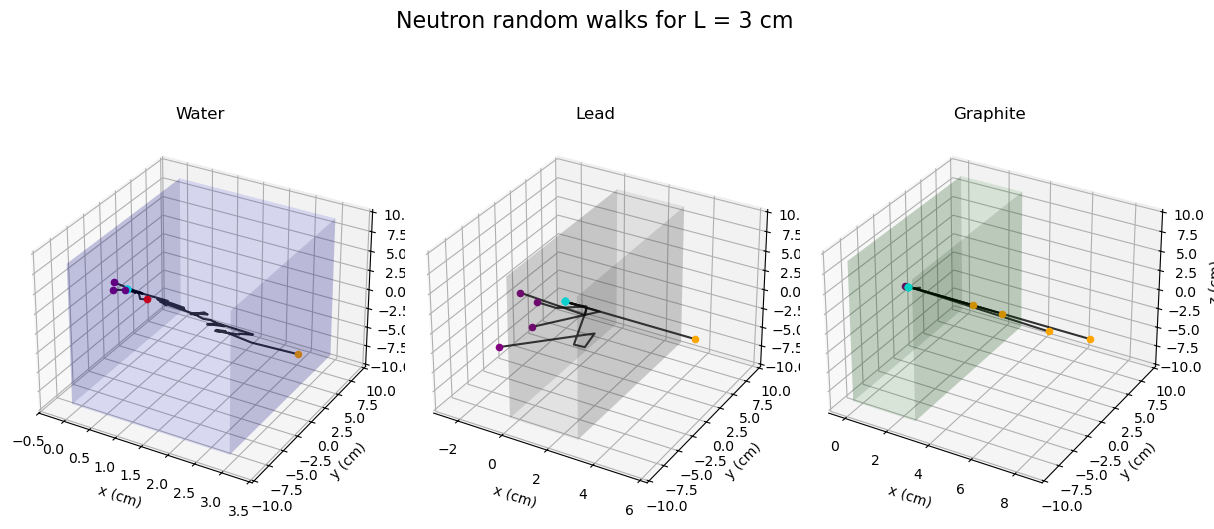

In [53]:
# Setting the slab thickness based on the mean free paths calculated from the code above. We set it to 3 cm to get a good representation of all processes involved.   
slab_thickness = 3  # in cm

# Defining a new 3D figure and giving the main title.
fig, axes = plt.subplots(1, 3, subplot_kw={'projection': '3d'}, figsize = (12,6))
plt.suptitle(f"Neutron random walks for L = {slab_thickness} cm", fontsize = 16)

# Calling the function to plot the path for neutrons in each material. We set the number of neutrons being simulated to be 5.
for ax, (name, data) in zip(axes, material_properties.items()):
    
    plot_neutron_paths(name, data, slab_thickness, ax, n_neutrons = 5)
    
plt.tight_layout()
plt.show()

The random-walk plots show example neutron trajectories through slabs of water, lead, and graphite for L = 3 cm. The starting points are shown in cyan, absorbed neutrons in red, transmitted neutrons in orange, and reflected neutrons in purple. The coloured transparent region represents the slab volume between x = 0 and x = L. This is only a visual guide, since the simulated slab is defined by its x-boundaries. A low transparency is used so that the neutron paths remain visible.

Since only a small number of neutrons are plotted, the exact paths and outcomes change each time the cell is run. These plots are therefore intended as a qualitative check of the simulation logic rather than a precise comparison between materials. However, it should be evident that there are far more interactions in water than in lead or graphite, with far fewer transmissions, as expected. 

Each neutron enters the slab at x = 0 travelling initially in the +x direction. After each interaction, the neutron is either absorbed or scattered into a new isotropic direction. The plotted paths show the random nature of the process: some neutrons scatter many times before escaping or being absorbed, while others leave the slab after relatively few interactions. Neutrons ending to the left of the first plane are reflected, neutrons ending beyond the second plane are transmitted, and neutrons ending inside the slab are absorbed. This confirms that the code is correctly applying the boundary checks and interaction rules for individual neutron paths.

A larger number of neutrons is required to calculate reliable absorption, reflection, and transmission probabilities. This is done in the next section without plotting the individual paths.

## 7. Quantifying Absorption, Reflection, and Transmission

The previous section visualised a small number of neutron random walks. To obtain meaningful numerical probabilities, the simulation must now be repeated for a large number of neutrons without plotting each individual path. For this part, the slab thickness is later set to L = 10 cm, as specified in the project brief. Each neutron is tracked until it is absorbed, reflected, or transmitted. The final counts are then used to calculate the absorption, reflection, and transmission fractions:

\begin{equation}
f_A = \frac{N_A}{N}
\end{equation}

\begin{equation}
f_R = \frac{N_R}{N}
\end{equation}

\begin{equation}
f_T = \frac{N_T}{N}
\end{equation}

where N is the total number of incident neutrons, and NA, NR, and NT are the numbers absorbed, reflected, and transmitted respectively.

### 7.1 Sampling the x-Component of the Scattering Direction

For the full three-dimensional visualisation, the complete isotropic direction vector was generated. However, for calculating whether a neutron is absorbed, reflected, or transmitted through a slab, only the x-coordinate of its motion affects the outcome. The y and z coordinates do not affect whether the neutron crosses the slab boundaries at x = 0 or x = L. The earlier isotropic direction function generated full three-dimensional unit vectors. However, for an isotropic distribution, the direction cosine along any axis is uniformly distributed between −1 and 1. Therefore, the x-component of the direction can be sampled directly as:

\begin{equation}
\mu = \cos(\theta_x) \sim U(-1,1)
\end{equation}

This is equivalent to generating a full isotropic unit vector and keeping only its x-component, but it is more efficient because the simulation only needs the x-direction cosine, and unnecessary calculations for theta and phi are avoided.

In [28]:
# Defining the simplified function to generate only x-components of isotropic unit vectors (1D scattering). This will be called in the main function.
def sample_unit_x(n):
    return np.random.uniform(-1, 1, n)

### 7.2 Vectorised Neutron Transport Function

The function below simulates many neutrons at the same time using NumPy arrays. Instead of tracking one neutron at a time, arrays are used to store the positions and x-direction cosines of all neutrons that are still active inside the slab.

At each iteration:

1. each active neutron is moved by an exponentially sampled step length;
2. neutrons with x < 0 are counted as reflected;
3. neutrons with x > L are counted as transmitted;
4. neutrons still inside the slab are tested for absorption;
5. surviving neutrons are scattered and assigned new isotropic x-direction cosines.

After each outcome is counted, those neutrons are removed from the active arrays. This makes the arrays shorter as the simulation progresses, improving the runtime because the code only updates neutrons that are still inside the slab. The optional `store_extra` argument is included for diagnostic plots. When it is set to `True`, the function also stores the absorption positions and the exit-direction cosines of reflected and transmitted neutrons.

In [29]:
# This is the main function to simulate and quantify neutron transport statistics.
def simulate_neutron_transport(material_name, material_data, slab_thickness, n_neutrons, store_extra = False):

    # These paramaters are only tracked for producing the absorption profile and cosines of transmitted and reflected neutrons.
    if store_extra:
        absorption_positions = []
        exit_directions_reflected = []
        exit_directions_transmitted = []

    # Extracting the values for the cross sections and mean free path.
    Sigma_a = material_data['Sigma_a']
    Sigma_t = material_data['Sigma_t']
    lambda_value = material_data['lambda']

    # Defining the probability of absorption.
    p_absorb = Sigma_a / Sigma_t

    # Initialising neutron state arrays.
    positions = np.zeros(n_neutrons)
    directions = np.ones(n_neutrons)

    # Initialising counters for every outcome.
    absorbed, reflected, transmitted = 0, 0, 0

    # Continue until all neutrons have reached an outcome.
    while len(positions) > 0:

        # Number of neutrons still active.
        N_active = len(positions)

        # Defining step lengths for all active neutrons.
        steps = -lambda_value * np.log(np.random.rand(N_active))

        # Updating positions.
        positions = positions + steps * directions

        # Finding reflected and transmitted neutrons.
        reflected_indices = np.argwhere(positions < 0).flatten()
        transmitted_indices = np.argwhere(positions > slab_thickness).flatten()

        # Counting reflected and transmitted neutrons.
        reflected += len(reflected_indices)
        transmitted += len(transmitted_indices)

        # Storing exit direction cosines if needed.
        if store_extra:
            
            exit_directions_reflected.extend(directions[reflected_indices])
            exit_directions_transmitted.extend(directions[transmitted_indices])

        # Mask for neutrons still inside the slab.
        inside_mask = (positions >= 0) & (positions <= slab_thickness)

        # Keeping only neutrons still inside.
        positions = positions[inside_mask]
        directions = directions[inside_mask]

        # If no neutrons remain inside, stop.
        if len(positions) == 0:
            break

        # Testing absorption for neutrons still inside the slab.
        absorption_mask = np.random.rand(len(positions)) < p_absorb
        # Finding absorbed neutrons.
        absorbed_indices = np.argwhere(absorption_mask).flatten()
        # Counting absorbed neutrons.
        absorbed += len(absorbed_indices)

        # Storing absorption positions if needed.
        if store_extra:
            absorption_positions.extend(positions[absorbed_indices])

        # Mask for neutrons that were not absorbed.
        scattered_mask = ~absorption_mask
        # Keeping only scattered neutrons.
        positions = positions[scattered_mask]
        directions = directions[scattered_mask]

        # Updating directions of scattered neutrons. They move on to the next step.
        directions = sample_unit_x(len(directions))

    # Returns the rates and the extra data for absoprtion profile and transmission/reflection cosines if needed.
    if store_extra:
        return {
            'absorbed': absorbed,
            'reflected': reflected,
            'transmitted': transmitted,
            'absorption_positions': np.array(absorption_positions),
            'mu_reflected': np.array(exit_directions_reflected),
            'mu_transmitted': np.array(exit_directions_transmitted)
        }

    return {
        'absorbed': absorbed,
        'reflected': reflected,
        'transmitted': transmitted
    }

This function returns the number of absorbed, reflected, and transmitted neutrons. Since every neutron eventually reaches one of these outcomes, the sum of these three counts should equal the total number of incident neutrons. The function is vectorised by updating all active neutrons simultaneously and removing neutrons once they have reached a final outcome. This is much faster than simulating each neutron separately, especially when repeating the calculation for many slab thicknesses and materials later in the project. This function was also validated by comparing it with the 3D random walk function (after adding counters to it) for a small number of neutrons, which gave identical results. This further validates the choice of only considering x-direction cosine.

### 7.3 Repeating the Transport Simulation

To reduce the effect of random fluctuations, the neutron transport simulation is repeated several times for each material. Each trial simulates the same number of incident neutrons and returns the fractions absorbed, reflected, and transmitted. The mean outcome fractions are calculated over the repeated trials. The standard deviation across trials measures how much the Monte Carlo result fluctuates between independent simulations, while the standard error on the mean estimates the uncertainty in the averaged result:

\begin{equation}
\sigma_{\bar{x}} = \frac{\sigma}{\sqrt{N_{\mathrm{trials}}}}
\end{equation}

When `store_extra=True`, the absorption positions are also stored so that an absorption profile can be plotted later as an additional diagnostic.

In [30]:
# Defining the function to repeat the simulation 10 times and average the results.
def repeat_transport(material_data, slab_thickness, n_neutrons, n_trials = 10, store_extra = False):
    
    # Defining an empty 2D array for storing the fractions for each outcome from each trial.
    rates = np.zeros((n_trials, 3))  # columns: absorbed, reflected, transmitted

    # Defining an array to store all absoprtion positions from the 10 simulations.
    all_absorption_positions = []

    # Looping over each trial.
    for i in range(n_trials):

        # Calling the function to run one trial.
        summary = simulate_neutron_transport(
            material_name = None,
            material_data = material_data,
            slab_thickness = slab_thickness,
            n_neutrons = n_neutrons,
            store_extra = store_extra
        )

        # Extracting the data for that trial.
        rates[i, 0] = summary['absorbed']/n_neutrons
        rates[i, 1] = summary['reflected']/n_neutrons
        rates[i, 2] = summary['transmitted']/n_neutrons
        
        # Storing the x-position of the absorption events. Only for plotting the absorption profile.
        if store_extra:
            all_absorption_positions.extend(summary['absorption_positions'])


    # Computing the mean fraction for each outcome from 10 trials.
    mean_rates = np.mean(rates, axis = 0)
    # Computing the standard deviation of the outcome fractions over the 10 trials.
    std_rates = np.std(rates, axis = 0, ddof = 1)
    # Computing the standard error on the mean.
    std_error_rates = std_rates / np.sqrt(n_trials)

     # Returns all the data including the absorption profile.
    if store_extra:
        return mean_rates, std_rates, std_error_rates, np.array(all_absorption_positions)

    return mean_rates, std_rates, std_error_rates

### 7.4 Transport Simulation at L = 10 cm

The project brief requires the absorption, reflection, and transmission fractions to be calculated for a slab thickness of L = 10 cm. For each material, 10000 neutrons are simulated per trial, and the simulation is repeated 10 times. The repeated trials are used to calculate mean outcome fractions and standard errors.

In [31]:
# Defining the number of neutrons, slab thickness, and number of repeated simulations.
n_neutrons = 10000
slab_thickness = 10
n_trials = 10

Now we run the simulation. The same simulation call also stores the absorption positions, which are used later for the optional absorption-profile diagnostic.

In [32]:
# Defining dictionaries to store the simulation results and absorption profiles.
transport_results = {}
absorption_profiles = {}

# Looping over each material.
for name, data in material_properties.items():

    # Calling the function to repeat the simulation and collect the data. We set store_extra = True as we will use this same call to produce the absorption profile.
    mean_rates, std_rates, std_error_rates, x_abs = repeat_transport(
        material_data = data,
        slab_thickness = slab_thickness,
        n_neutrons = n_neutrons,
        n_trials = n_trials,
        store_extra = True
    )

    # Storing the mean rates and standard errors for later use.
    transport_results[name] = {
        'mean_rates': mean_rates,
        'std_error_rates': std_error_rates
    }

    # Storing the absorption profile data.
    absorption_profiles[name] = x_abs

The mean absorption, reflection, and transmission fractions are first visualised using pie charts. These show the relative probability of each final neutron outcome for water, lead, and graphite at a slab thickness of L = 10 cm. The colour scheme is kept consistent throughout this section: red represents absorption, purple represents reflection, and orange represents transmission.

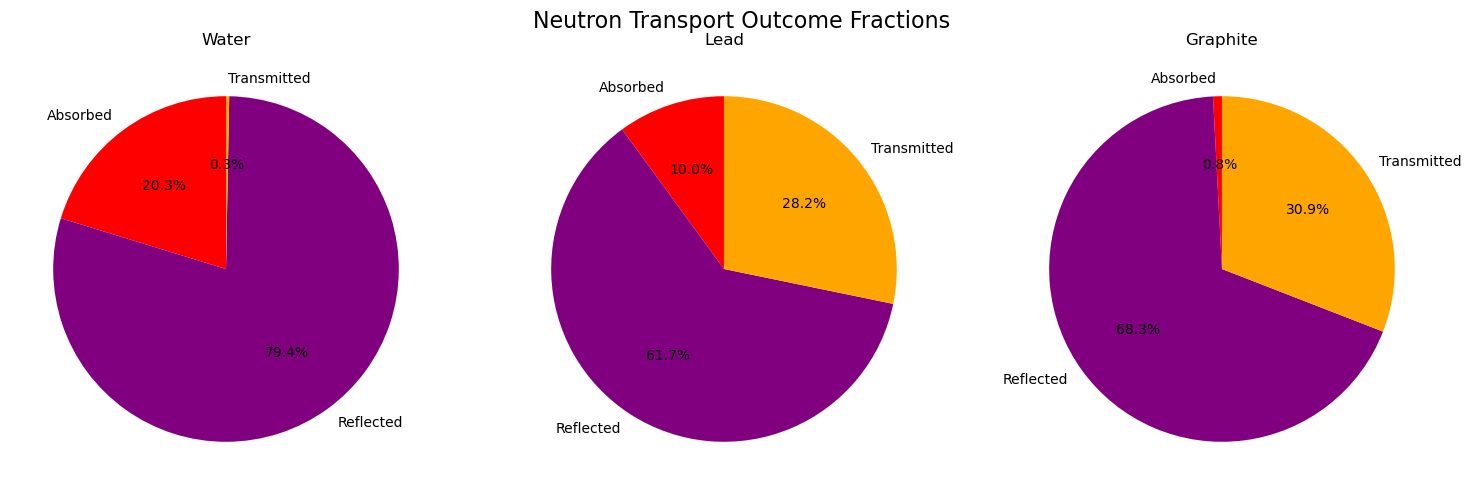

In [33]:
# Defining labels and colours for the 3 neutron outcomes.
labels = ['Absorbed', 'Reflected', 'Transmitted']
colors = ['red', 'purple', 'orange']

# Creating figure with 3 pie charts side-by-side.
fig, ax = plt.subplots(1, 3, figsize = (15, 5))

# Looping over each material.
for i, name in enumerate(material_properties.keys()):

    # Plotting pie chart using the mean rates from the simulation.
    ax[i].pie(
        transport_results[name]['mean_rates'],
        labels = labels,
        colors = colors,
        autopct = '%1.1f%%',
        startangle = 90
    )

    # Giving title for each material.
    ax[i].set_title(name)

# Giving the main title.
plt.suptitle('Neutron Transport Outcome Fractions', fontsize = 16)

plt.tight_layout()
plt.show()

The pie charts show that the dominant outcome depends strongly on the material. For water, most neutrons are reflected, with a significant absorbed fraction and very little transmission. This is consistent with water having a very short total mean free path due to strong scattering.

Lead and graphite both show larger transmitted fractions than water. Lead has a higher absorption fraction than graphite because its macroscopic absorption cross-section is larger. Graphite has very low absorption, so most neutrons are either reflected or transmitted after scattering. These pie charts provide a useful visual summary, but the numerical values and uncertainties are more clearly presented in a table in the next step.

The mean outcome fractions are displayed numerically with their standard errors. This table is the main quantitative result for the L = 10 cm transport simulation, since it gives the absorption, reflection, and transmission rates required by the project brief.

The entries are written as:

\begin{equation}
\mathrm{mean \ fraction} \pm \mathrm{standard \ error}
\end{equation}

where the standard error is calculated from the variation between the repeated Monte Carlo trials.

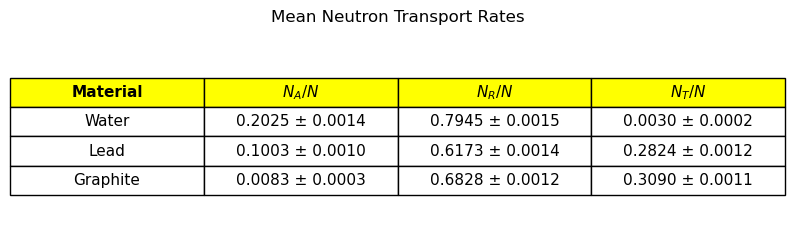

In [34]:
# Defining an empty list to store the table data.
table = []

# Looping over each material.
for name in material_properties.keys():

    # Extracting the mean rates and standard errors.
    mean_rates = transport_results[name]['mean_rates']
    std_error_rates = transport_results[name]['std_error_rates']

    # Appending the data for this material to the table.
    table.append([
        name,
        f"{mean_rates[0]:.4f} ± {std_error_rates[0]:.4f}",
        f"{mean_rates[1]:.4f} ± {std_error_rates[1]:.4f}",
        f"{mean_rates[2]:.4f} ± {std_error_rates[2]:.4f}"
    ])

# Defining the headers for the table.
headers = ['Material', r'$N_A/N$', r'$N_R/N$', r'$N_T/N$']

# Creating a matplotlib figure for the table.
fig, ax = plt.subplots(figsize = (8, 2.5))

# Turning off axes since we only want the table.
ax.axis('off')

# Creating the table.
table_plot = ax.table(cellText = table, colLabels = headers, cellLoc = 'center', loc = 'center')

# Formatting the table.
table_plot.auto_set_font_size(False)
table_plot.set_fontsize(11)
table_plot.scale(1.2, 1.8)

# Making header row bold and shaded.
for (row, col), cell in table_plot.get_celld().items():

    # Header row.
    if row == 0:
        
        cell.set_text_props(weight = 'bold')
        cell.set_facecolor('yellow')

# Giving a title.
plt.title('Mean Neutron Transport Rates', pad = 15)

plt.tight_layout()
plt.show()

For L = 10 cm, water has the smallest transmission fraction. This is expected because water has the shortest total mean free path, so neutrons scatter many times inside the slab and are very unlikely to pass straight through. Most neutrons in water are reflected, while a significant fraction are absorbed. Lead and graphite have much larger transmission fractions than water, and lead has a noticeably larger absorption fraction than graphite. Graphite absorbs very few neutrons, so most neutrons are either reflected or transmitted after repeated scattering.

The uncertainties quoted in the table are small because it is the standard error on the mean over 10 independent Monte Carlo trials. This measures the uncertainty in the averaged outcome fraction, rather than the spread of individual trial results.The three fractions for each material sum to approximately 1, confirming that all simulated neutrons are accounted for as absorbed, reflected, or transmitted. This table is also consistent with the pie chart.

### 7.5 Additional Diagnostic Plots: Reflection and Transmission Direction Cosines, and Absorption Profiles

As an additional check, two further diagnostic plots are produced: the exit direction cosines of reflected and transmitted neutrons, and the spatial distribution of absorption events inside the slab. These plots are not used directly to calculate the final transport rates, but they help test whether the simulation behaves physically and whether the boundary conditions are being applied correctly.

The x-direction cosine μ is stored for neutrons that leave the slab. For reflected neutrons, the final x-direction should be negative because they leave through the x = 0 boundary. For transmitted neutrons, the final x-direction should be positive because they leave through the x = L boundary.

Therefore, the reflected distribution should lie mostly in the range:

\begin{equation}
-1 \leq \mu < 0
\end{equation}

and the transmitted distribution should lie mostly in the range:

\begin{equation}
0 < \mu \leq 1
\end{equation}

This provides a useful validation that reflected and transmitted neutrons are being classified consistently with their final direction of motion. Note that this is calculated for just one simulation.

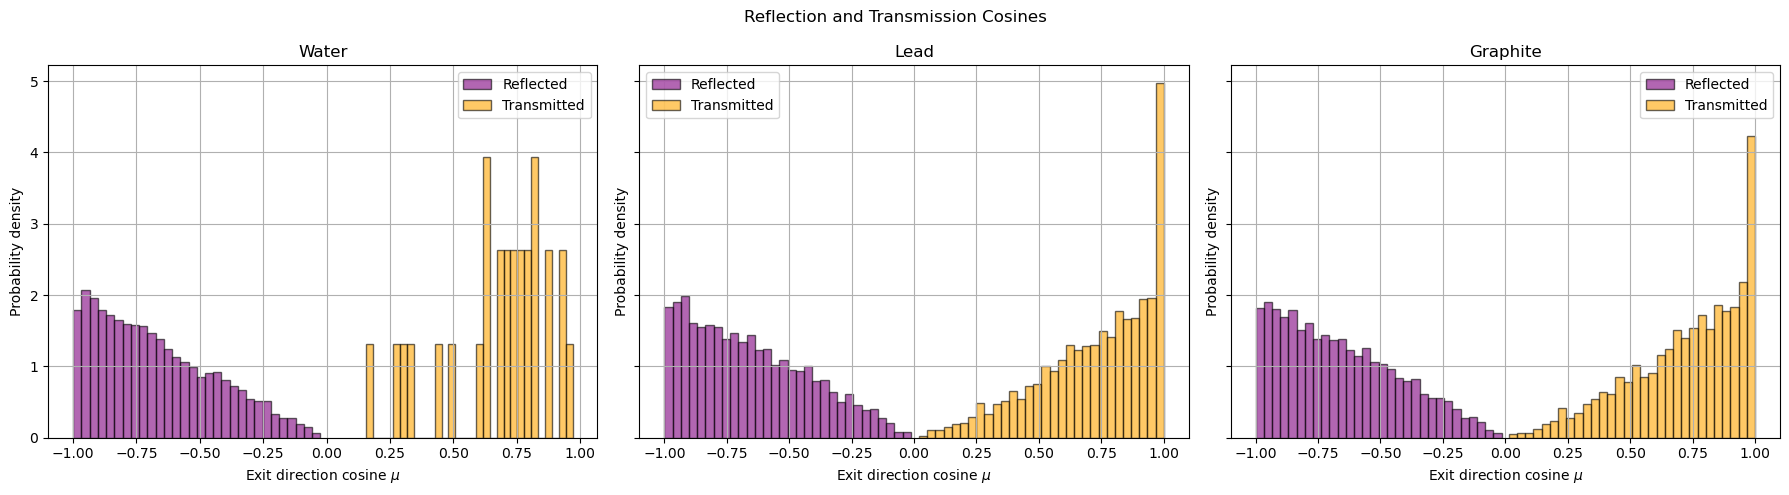

In [35]:
n_neutrons = 10000  # We simulate 10000 neutrons
slab_thickness = 10 # in cm
# Defining dictionary to store the extracted cosines of exitting neutrons for all materials.
cosines = {}

# We call the function in this loop.
for name, data in material_properties.items():
    
    # Fetching the data for each material by calling the function.
    summary = simulate_neutron_transport(name, data, slab_thickness, n_neutrons, store_extra = True)

    # Extracting the cosines of exitting neutrons for each material. We will use this dictionary for plotting in the next cell.
    cosines[name] = {
        'reflected': summary['mu_reflected'],
        'transmitted': summary['mu_transmitted']
    }
# Defining a figure with 3 subplots
fig, ax = plt.subplots(1, 3, figsize = (18, 5), sharey = True)
# Iterating over each material to plot the cosines of exitting neutrons.
for i, name in enumerate(material_properties.keys()):

    # Plotting the histogram of cosines for neutrons that were reflected.
    ax[i].hist(cosines[name]['reflected'], bins = 30, alpha = 0.6, density = True, color = 'purple', label = 'Reflected', edgecolor = 'black')
    # Plotting the histogram of cosines for neutrons that were transmitted.
    ax[i].hist(cosines[name]['transmitted'], bins = 30, alpha = 0.6, density = True, color = 'orange', label = 'Transmitted', edgecolor = 'black')

    # Giving a title and labeling the axes.
    ax[i].set_title(name)
    ax[i].set_xlabel(r'Exit direction cosine $\mu$')
    ax[i].set_ylabel('Probability density')
    # Displaying legend and grid.
    ax[i].grid(True)
    ax[i].legend()

# Giving the main title.
plt.suptitle('Reflection and Transmission Cosines')
plt.tight_layout()
plt.show()

The reflected neutrons have negative exit direction cosines, while the transmitted neutrons have positive exit direction cosines, as expected. This confirms that the simulation is correctly distinguishing neutrons leaving through the left boundary from those leaving through the right boundary.

The distributions are not flat because the exiting neutrons are a selected subset of all scattered neutrons. Neutrons travelling more strongly towards a boundary are more likely to escape, so the transmitted distribution is weighted towards μ close to +1 and the reflected distribution is weighted towards μ close to −1. This behaviour is physically reasonable and supports the boundary-checking logic used in the transport simulation.

The absorption positions are also stored to examine where inside the slab absorption events occur. This gives a spatial profile of neutron absorption as a function of x-position. The histogram shows the probability density of absorption events inside the slab, restricted to the region:

\begin{equation}
0 \leq x \leq L
\end{equation}

This diagnostic helps show how the material properties affect where neutrons are most likely to be absorbed after entering the slab.

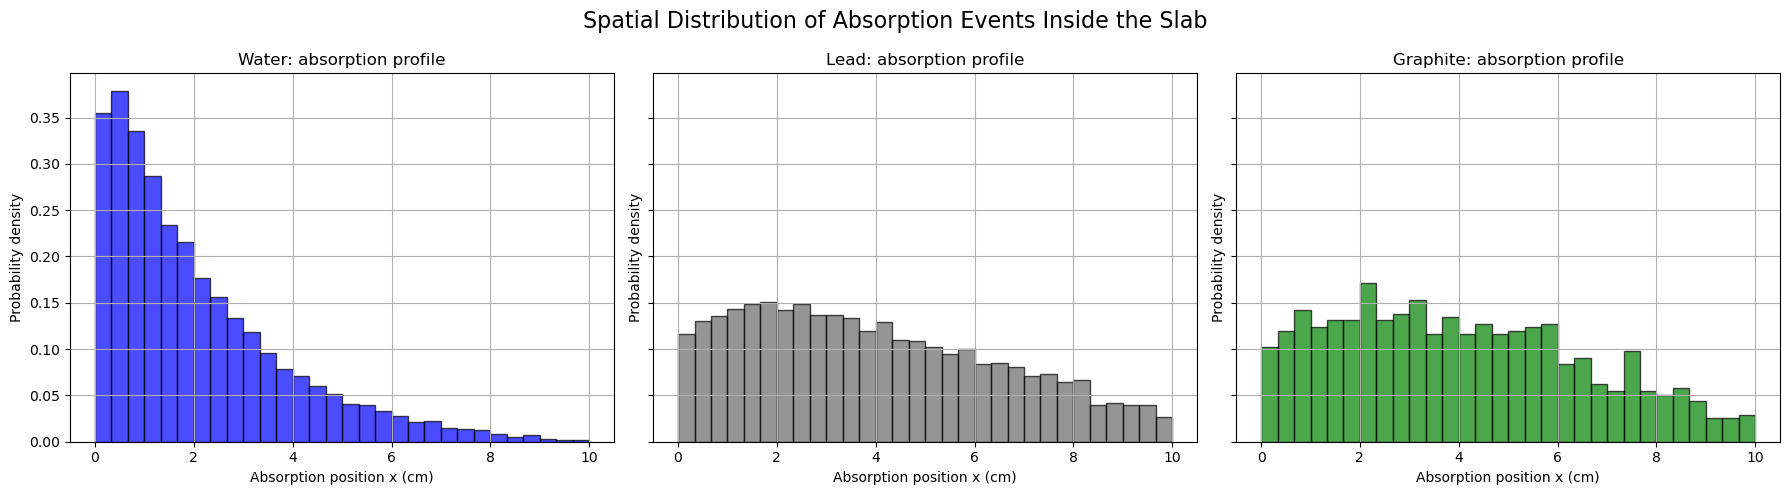

In [36]:
# Defining a figure to produce absorption profile plots
fig, axes = plt.subplots(1, 3, figsize = (18, 5), sharey = True)
# Defining a list of colors to represent each material.
colors = ['blue', 'dimgray', 'green']

# Looping over each material and its color.
for ax, (name, color) in zip(axes, zip(material_properties.keys(), colors)):

    # Fetching the absorption profile of the material.
    x_abs = absorption_profiles[name]
    
    # Producing a histogram of the absorption profile.
    ax.hist(x_abs, bins = 30, range = (0, slab_thickness), density = True, color = color, alpha = 0.7, edgecolor = 'black')

    # Giving a title and labeling the axes
    ax.set_title(f"{name}: absorption profile")
    ax.set_xlabel('Absorption position x (cm)')
    ax.set_ylabel('Probability density')
    # Displaying gird.
    ax.grid(True)

# Giving main title.
plt.suptitle('Spatial Distribution of Absorption Events Inside the Slab', fontsize = 16)
plt.tight_layout()
plt.show()

The absorption profile for water is strongly concentrated near the entrance side of the slab. This is expected because water has the shortest total mean free path, so neutrons undergo many interactions soon after entering. Since water also has a larger absorption probability than graphite, many absorption events occur relatively close to x = 0. Lead shows a broader absorption profile across the slab. This is consistent with its longer total mean free path compared with water, allowing neutrons to penetrate further before being absorbed. Graphite has a much lower absorption probability, so fewer absorption events occur overall. The absorption profile is therefore noisier, but it is spread across a wider region of the slab. This is consistent with graphite being weakly absorbing compared with water and lead.

These absorption profiles are additional qualitative checks and are not required for the main outcome-rate calculation, but they provide useful physical insight into the simulated transport process.

## 8. Variation of Transport Rates with Slab Thickness

The next part of the project investigates how the absorption, reflection, and transmission probabilities change as the slab thickness is varied. The simulation is repeated for 20 slab thicknesses from 1 cm to 20 cm for water, lead, and graphite. For each thickness, 10000 neutrons are simulated per trial and the calculation is repeated over 10 trials. The mean outcome rates and standard errors are then stored for plotting.

In [37]:
# We define an array of 20 slab thicnkesses from 1 cm to 20 cm.
thickness_values = np.linspace(1, 20, 20)
# We define the number of neutrons being simulated.
n_neutrons = 10000
n_trials = 10

### 8.1 Running the Simulation Over Different Slab Thicknesses

For each material and each slab thickness, the transport simulation is repeated using the `repeat_transport()` function. The mean absorption, reflection, and transmission rates are stored, along with the standard error on each mean. No extra diagnostic data are stored in this section because only the final outcome rates are needed.

In [38]:
# Defining the dictionary to store the fractions and uncertainties on the fractions for each outcome for each material.
results = {
    material: {
        'A': [], 'R': [], 'T': [],
        'A_err': [], 'R_err': [], 'T_err': []
    }
    for material in material_properties.keys()
}
# Looping over each material.
for name, data in material_properties.items():

    # We run the simulation for each value of thickness.
    for L in thickness_values:

        # Extracting the results of 10 simulations for one thickness. Note that we set store_extra to false because we do not need the absorption profile here.
        mean_rates, std_rates, std_error_rates = repeat_transport(
            material_data = data,
            slab_thickness = L,
            n_neutrons = n_neutrons,
            n_trials = n_trials,
            store_extra = False
        )

        # Calculating the fractions and appending it to the dictionary
        results[name]['A'].append(mean_rates[0])
        results[name]['R'].append(mean_rates[1])
        results[name]['T'].append(mean_rates[2])
        # Storing the standard error on the mean fraction.
        results[name]['A_err'].append(std_error_rates[0])
        results[name]['R_err'].append(std_error_rates[1])
        results[name]['T_err'].append(std_error_rates[2])

### 8.2 Plotting Outcome Rates Against Slab Thickness

The stored results are plotted as absorption, reflection, and transmission rates against slab thickness. Error bars show the standard error on the mean from the repeated Monte Carlo trials. The same material colour scheme is used throughout: blue for water, dimgray for lead, and green for graphite.

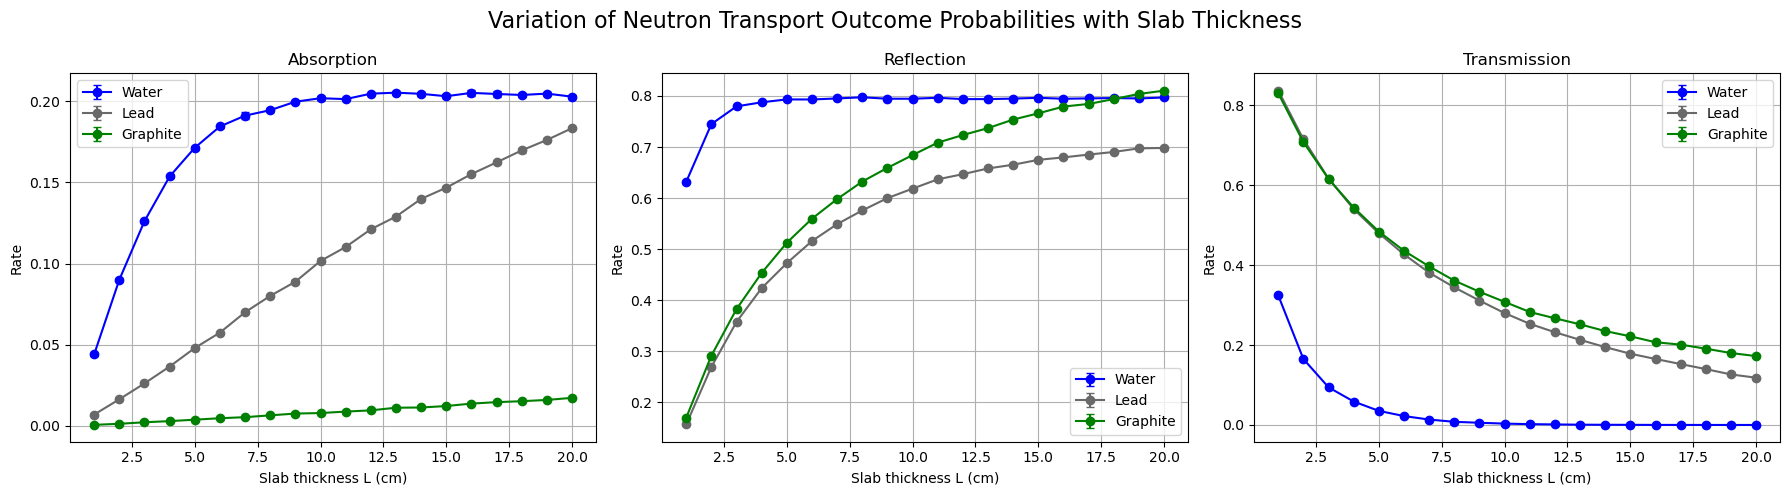

In [39]:
# Defining the figure and giving the maintitle.
fig, ax = plt.subplots(1, 3, figsize = (18, 5))
plt.suptitle('Variation of Neutron Transport Outcome Probabilities with Slab Thickness', fontsize = 16)

# Defining a dictionary of each outcome to loop over for plotting.
processes = {
    'A': 'Absorption',
    'R': 'Reflection',
    'T': 'Transmission'
}

# We iterate over the index number, and the items of the dictionary of processes.
for j, (key, process_name) in enumerate(processes.items()):

    # Defining a list of colors to represent each material in the plot.
    colors = ['blue', 'dimgray', 'green']
    # Looping over the data for each material and color for the mateial at the same time.
    for name, color in zip(material_properties.keys(), colors):

        # Plotting the error bar for thickness vs transport outcome rate using the dictionary of results form the simulation.
        ax[j].errorbar(
            thickness_values,
            results[name][key],
            yerr = results[name][key + '_err'],
            marker = 'o',
            color = color,
            capsize = 3,
            label = name)

        # Giving a title and labeling the axes.
        ax[j].set_title(process_name)
        ax[j].set_xlabel("Slab thickness L (cm)")
        ax[j].set_ylabel("Rate")
        # Displaying legend and grid.
        ax[j].grid(True)
        ax[j].legend()

plt.tight_layout()
plt.show()    

The plots show clear differences in how the three materials affect neutron transport as slab thickness increases.

For water, the transmission probability decreases very rapidly and becomes almost zero for thicker slabs. This is expected because water has the shortest total mean free path, causing neutrons to scatter many times over a short distance. The reflection probability is therefore high, while the absorption probability rises initially and then levels off around 0.2.

Lead and graphite show slower decreases in transmission with thickness. Their total mean free paths are longer than that of water, so neutrons can penetrate further before interacting. Lead has a larger absorption rate than graphite because its macroscopic absorption cross-section is larger. Graphite remains weakly absorbing across the full thickness range, so most neutrons are either reflected or transmitted.

Overall, increasing slab thickness reduces transmission and increases the probability that neutrons either scatter back out of the slab or are absorbed inside it.

## 9. Determining Attenuation Lengths from Transmission Rates

The final required analysis is to estimate a characteristic attenuation length for each material using the simulated transmission rates. As the slab thickness increases, the transmission rate decreases. This decrease can be approximately modelled using an exponential attenuation law:

\begin{equation}
T(L) = T_0 e^{-L/\lambda}
\end{equation}

where T(L) is the transmission rate for slab thickness L, T0 is a constant, and λ is the characteristic attenuation length.

Taking the natural logarithm gives a linear relationship:

\begin{equation}
\ln(T) = \ln(T_0) - \frac{L}{\lambda}
\end{equation}

Therefore, λ can be determined from the gradient of a linear fit to ln(T) against L. If the fitted gradient is m, then:

\begin{equation}
\lambda = -\frac{1}{m}
\end{equation}

The uncertainty in ln(T) is found by error propagation:

\begin{equation}
\sigma_{\ln(T)} = \frac{\sigma_T}{T}
\end{equation}

A weighted linear fit is then performed using these uncertainties. Any zero transmission values are removed before taking the logarithm, because ln(0) is undefined. This process is identical to how the attenuation length was calculated when only absorption was involved.

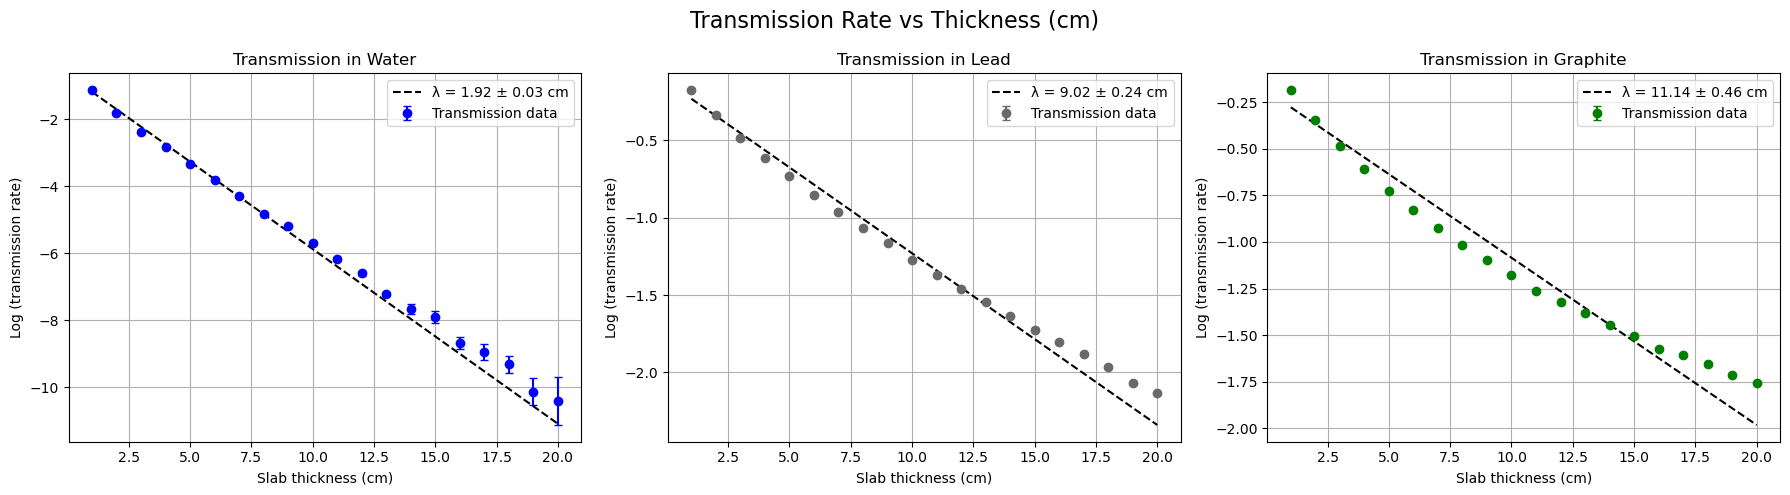

In [40]:
# Defining an empty list to store attenuation lengths. This will be used to produce a table.
attenuation_table = []
# Defining an array of colors to represent each material in the plot.
colors = ['blue', 'dimgray', 'green']
# Defining the figure.
fig, ax = plt.subplots(1, 3, figsize = (18,5))

# We iterate over the index number, color and name of the material.
for i, (color, name) in  enumerate(zip(colors, material_properties.keys())):

    # Converting the values of transmission rates, error on the transmission rates, and the thicknesses to arrays.
    T_values = np.array(results[name]['T'])
    L_values = np.array(thickness_values)
    T_errors = np.array(results[name]['T_err'])

    # Mask to remove 0 transmission values.
    mask = (T_values > 0) & (T_errors > 0)
    T_fit = T_values[mask]
    L_fit = L_values[mask]
    T_err_fit = T_errors[mask]

    # Taking the log of the transmission rates and error on transmission rates.
    log_T = np.log(T_fit)
    log_T_err = T_err_fit/T_fit # This is the uncertainty on log(T) after error propagation.

    # Mask to avoid zero errors casuing problems while fitting.
    valid = log_T_err > 0
    log_T = log_T[valid]
    log_T_err = log_T_err[valid]
    L_fit = L_fit[valid]

    # Performing a weighted linear fit in the log-space using polyfit to extract the slope of the fit.
    coeffs, cov = np.polyfit(L_fit, log_T, 1, w = 1/log_T_err, cov = True)
    # The slope, error on the slope, and intercept of the fit are extracted.
    slope = coeffs[0]
    intercept = coeffs[1]
    slope_err = np.sqrt(cov[0, 0]) # The error on the slope of the fitted line is found using the covariance matrix.

    # We now calculate the attenuation length and its error from the slope.
    lambda_att = -1 / slope
    lambda_att_err = slope_err / slope**2 # This is the error on the attenuation length after error propagation.

    # Appending the material name, attenuation length, and the error to the list as one row of the table.
    attenuation_table.append([
        name,
        f"{lambda_att:.3f}",
        f"{lambda_att_err:.3f}"
    ])

    # Plotting an error bar for the raw data in log-space.
    ax[i].errorbar(L_fit, log_T, yerr = log_T_err, fmt = 'o', color = color, capsize = 3, label = 'Transmission data')
    # Plotting the linear fit. We use polyval to fit the coefficients extracted from polyfit to the thickness values.
    ax[i].plot(L_fit, np.polyval(coeffs, L_fit), 'k--', label = f"λ = {lambda_att:.2f} ± {lambda_att_err:.2f} cm")

    # Giving a title and labeling the axes.
    ax[i].set_title(f"Transmission in {name}")
    ax[i].set_xlabel('Slab thickness (cm)')
    ax[i].set_ylabel('Log (transmission rate)')
    # Displaying legend and grid.
    ax[i].grid(True)
    ax[i].legend()

plt.suptitle('Transmission Rate vs Thickness (cm)', fontsize = 16)
plt.tight_layout()
plt.show()

The logarithmic transmission plots show an approximately linear decrease with slab thickness, supporting the use of an exponential attenuation model to extract a characteristic attenuation length.

Water has the shortest fitted attenuation length, meaning its transmission rate falls most rapidly with increasing slab thickness. This is consistent with the earlier transport-rate plots, where water transmission becomes almost zero for thicker slabs. Lead and graphite have longer fitted attenuation lengths, so their transmission rates decrease more slowly. Graphite has the largest fitted attenuation length in this simulation, meaning it remains comparatively more transmitting over the thickness range considered. However, the graphite fit is less perfectly linear than water because scattering and reflection effects make the transmission behaviour more complicated than a simple exponential law. The fitted attenuation lengths should therefore be interpreted as effective attenuation lengths for the full scattering and absorption transport simulation, rather than as the microscopic mean free paths calculated earlier.

The fitted attenuation lengths are summarised below. These values are also shown on the plots, but the table provides a clearer numerical summary of the final fitted results.

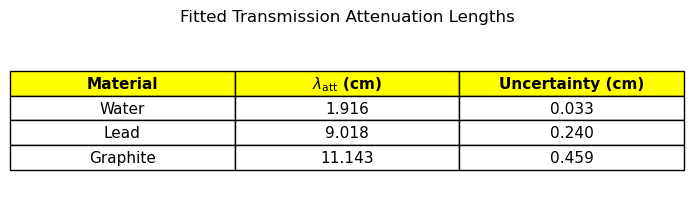

In [41]:
# Defining the headers for the attenuation length summary table.
headers = ['Material', r'$\lambda_{\mathrm{att}}$ (cm)', 'Uncertainty (cm)']

# Creating a matplotlib figure for the table.
fig, ax = plt.subplots(figsize = (7, 2.2))

# Turning off the axes since only the table is required.
ax.axis('off')

# Creating the table using the attenuation length data calculated from the fits.
table_plot = ax.table(cellText = attenuation_table, colLabels = headers, cellLoc = 'center', loc = 'center')

# Formatting the table.
table_plot.auto_set_font_size(False)
table_plot.set_fontsize(11)
table_plot.scale(1.2, 1.6)

# Making the header row bold and shaded.
for (row, col), cell in table_plot.get_celld().items():

    # Header row.
    if row == 0:
        cell.set_text_props(weight = 'bold')
        cell.set_facecolor('yellow')

# Giving the table a title.
plt.title('Fitted Transmission Attenuation Lengths', pad = 15)

plt.tight_layout()
plt.show()

Overall, the fitted attenuation lengths provide a compact way to compare the shielding effectiveness of the three materials: smaller attenuation length corresponds to stronger reduction of transmitted neutrons.

## 10. Woodcock Method for Two Adjacent Slabs

As an extension, the Woodcock method is used to simulate neutron transport through two adjacent slabs of different materials. Each slab has thickness 10 cm, so the full system extends from x = 0 cm to x = 20 cm. The Woodcock method allows the neutron to be transported through regions with different macroscopic cross-sections using a single global interaction cross-section. This is chosen as the largest total macroscopic cross-section among the materials present:

\begin{equation}
\Sigma_{\mathrm{max}} = \max(\Sigma_{t,1}, \Sigma_{t,2})
\end{equation}

Step lengths are then sampled using this global cross-section:

\begin{equation}
s = -\frac{\ln(u)}{\Sigma_{\mathrm{max}}}
\end{equation}

At the end of each step, the local material is identified from the neutron's x-position. The collision is accepted as a real collision with probability:

\begin{equation}
P_{\mathrm{real}} = \frac{\Sigma_t(x)}{\Sigma_{\mathrm{max}}}
\end{equation}

If the collision is rejected, it is treated as a virtual collision: the neutron position is updated, but no absorption or scattering occurs. If the collision is accepted, the neutron is either absorbed or scattered according to the local material properties.

### 10.1 Materials Used for Woodcock Tracking

A separate material dictionary is defined for the Woodcock method. The real material data for water, lead, and graphite are included using the macroscopic cross-sections calculated earlier. Additional test materials are also included for validation and visualisation(concrete and cadmium). In particular, the example low-Σ and high-Σ materials create a strong contrast in total cross-section, making virtual collisions easier to demonstrate visually. Concrete and cadmium are included as illustrative test materials with representative macroscopic cross-sections, not as part of the original project data.

In [42]:
# Defining a separate dictionary of materials for visualising the Woodcock method. The extra materials are included only for validation and visual demonstration.
woodcock_materials = {

    # Real materials. Same data as found before.
    'Water': {
        'Sigma_a': Sigma_a[0],
        'Sigma_t': Sigma_t[0]
    },

    'Lead': {
        'Sigma_a': Sigma_a[1],
        'Sigma_t': Sigma_t[1]
    },

    'Graphite': {
        'Sigma_a': Sigma_a[2],
        'Sigma_t': Sigma_t[2]
    },

    # Defining cross-sections for additional materials like concrete and cadmium, commonly used for shielding.
    'Concrete': {
        'Sigma_a': 0.010,
        'Sigma_t': 0.35
    },

    'Cadmium': {
        'Sigma_a': 2.00,
        'Sigma_t': 2.50
    },
        
    # Example low-interaction material
    'Example Low Sigma': {
        'Sigma_a': 0.01,
        'Sigma_t': 0.01
    },

    # Example high-interaction material
    'Example High Sigma': {
        'Sigma_a': 0.01,
        'Sigma_t': 0.5
    }

}

### 10.2 Single-Neutron Woodcock Path

The first material occupies 0 cm ≤ x < 10 cm, and the second material occupies 10 cm ≤ x ≤ 20 cm. The neutron starts at x = 0 travelling in the +x direction. At each Woodcock step, the neutron is moved using the global cross-section Σmax. The material at the new x-position is then identified. The function for this is defined below.

In [43]:
# This is the function to check which material the neutron is in at the end of every step.
def get_material_at_x(x, material_1, material_2):
    # Wd define material 1 as a slab from 0-10cm
    if 0 <= x < 10:
        return material_1
    # We define material 2 as a slab from 10-20cm
    elif 10 <= x <= 20:
        return material_2
    else:
        return None

If the sampled collision is virtual, the neutron continues in the same direction. If the collision is real, the neutron is either absorbed or scattered. The function below simulates one neutron through two adjacent slabs. This version stores the full three-dimensional path so that a few example trajectories can be plotted.

In [44]:
# Defining the function to produce a 3D random walk for a single neutron in 2 slabs of materials using Woodcock method.
def woodcock_single_neutron_path(material_1, material_2):

    # Defining the thicknesses of both the slabs and calculating the total thickness.
    L1 = 10
    L2 = 10
    total_L = L1 + L2

    # Defining the global cross section. This is the maximum total macroscopic cross section out of the two materials.
    Sigma_max = max(material_1['Sigma_t'], material_2['Sigma_t'])

    # Defining the arrays of position and direction of the neutron in 3D.
    position = np.array([0.0, 0.0, 0.0])   # Neutron initially starts from (0,0,0).
    direction = np.array([1.0, 0.0, 0.0])  # Neutron initially moves in +x direction.

    # Making a copy of the position array to store the path. This will be used for plotting.
    path = [position.copy()]
    
    # This array will store the type of collision at each Woodcock step. This will be displayed.
    collision_types = []   # virtual, scatter, absorbed

    # The neutron keeps moving until it reaches an outcome.
    while True:

        # Defining a Woodcock step using the global cross section and updating the position and path.
        step_length = -np.log(np.random.rand()) / Sigma_max
        new_position = position + step_length * direction
        path.append(new_position.copy())

        # Extracting the x position of the neutron after the step.
        x = new_position[0]

        # Checking if neutron bounced back and left the system by reflection.
        if x < 0:
            # Path ends here. Returns path and outcome.
            return np.array(path), collision_types, 'reflected'

        # Checking if neutron fully transmitted through the system.
        if x > total_L:
            # Path ends here. Returns path and outcome.
            return np.array(path), collision_types, 'transmitted'

        # Checking which material the neutron is currently in.
        mat = get_material_at_x(x, material_1, material_2)

        # Deciding if a real or fictitious collision occurred. This probability measure for real collision will be very low for the material with lower cross-section.
        if np.random.rand() > mat['Sigma_t'] / Sigma_max:
            
            # If fictitious collision, no physics occurs and the direction stays the same. Neutron proceeds to next step.
            collision_types.append('virtual')
            position = new_position
            continue

        # If real collision, decide if absorption or scattering like before.
        if np.random.rand() < mat['Sigma_a'] / mat['Sigma_t']:
            
            # If absorbed, neutron path ends here. Returns outcome.
            collision_types.append('absorbed')
            return np.array(path), collision_types, 'absorbed'

        # If scattered, neutron proceeds to next Woodcock step in a different direction.
        collision_types.append('scatter')
        position = new_position
        direction = isotropic_unit_vector(1).flatten()

Now we can plot the 3D random walk for 2 materials.

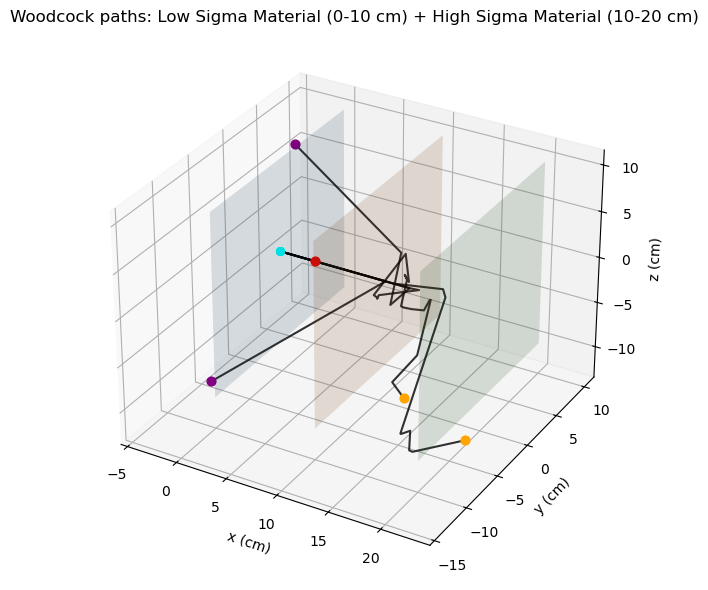

In [45]:
# Defining the function for plotting and displaying the 3D paths from the simulation.
def plot_woodcock_paths(material_1_name, material_2_name, material_1, material_2, n_neutrons = 5):

    # Defining a new figure.
    fig = plt.figure(figsize = (9, 6))
    ax = fig.add_subplot(111, projection = '3d')

    # Defining colours for final outcomes.
    outcome_colors = {
        'absorbed': 'red',
        'reflected': 'purple',
        'transmitted': 'orange',
        'max_steps_reached': 'black'
    }

    # Looping over each neutron.
    for i in range(n_neutrons):

        # Calling the function to simulate one 3D neutron random walk using the Woodcock method.
        path, collision_types, outcome = woodcock_single_neutron_path(material_1, material_2)

        # Plotting the full 3D path of the neutron.
        ax.plot(path[:, 0], path[:, 1], path[:, 2], alpha = 0.8, color = 'black')

        # Displaying the starting point of the neutron path.
        ax.scatter(path[0, 0], path[0, 1], path[0, 2], color = 'cyan', s = 30)

        # Displaying the ending point of the neutron path using the colour of its outcome.
        ax.scatter(path[-1, 0], path[-1, 1], path[-1, 2],
                   color = outcome_colors[outcome], s = 40)

    # Displaying slab boundaries at x = 0, 10, 20 cm.
    plane_size = 10
    y = np.linspace(-plane_size, plane_size, 20)
    z = np.linspace(-plane_size, plane_size, 20)
    Y, Z = np.meshgrid(y, z)

    # Producing the boundaries.
    for xpos in [0, 10, 20]:
        X = xpos * np.ones_like(Y)
        ax.plot_surface(X, Y, Z, alpha = 0.15)

    # Giving a title and labelling the axes.
    ax.set_title(f"Woodcock paths: {material_1_name} (0-10 cm) + {material_2_name} (10-20 cm)")
    ax.set_xlabel('x (cm)')
    ax.set_ylabel('y (cm)')
    ax.set_zlabel('z (cm)')

    plt.tight_layout()
    plt.show()

# Calling the function to plot 3D walk.
plot_woodcock_paths(
    'Low Sigma Material',
    'High Sigma Material',
    woodcock_materials['Example Low Sigma'],
    woodcock_materials['Example High Sigma'],
    n_neutrons = 5
)

The plot shows example Woodcock-tracked neutron paths through two adjacent slabs. The planes mark the boundaries at x = 0 cm, x = 10 cm, and x = 20 cm. The middle plane separates the two materials. The example shown uses a low-Σ material followed by a high-Σ material, which makes the purpose of the Woodcock method easier to visualise. In the low-cross-section region, many proposed collisions are likely to be virtual because the local total cross-section is much smaller than Σmax. The path is likely to be a straight line here. However, n the high-cross-section region, a larger fraction of proposed collisions are accepted as real interactions.

This plot is only a qualitative demonstration of the method. The actual stretch-task result requires simulating many neutrons and calculating the transmitted fraction through two adjacent 10 cm slabs.

### 10.3 Vectorised Woodcock Transport Function

After visualising a few individual Woodcock paths, the method is now implemented in a vectorised form so that many neutrons can be simulated efficiently. The geometry consists of two adjacent slabs: the first slab extends from x = 0 to x = 10 cm, and the second slab extends from x = 10 cm to x = 20 cm.

The Woodcock method samples all candidate steps using the majorant cross-section Σmax. This means that the same step-sampling rule can be used across both materials, even if their total cross-sections are different. After each candidate step, the local material is identified from the neutron's x-position.

A candidate collision is then classified as either real or fictitious. The probability of a fictitious collision is:

\begin{equation}
P_{\mathrm{fic}} = 1 - \frac{\Sigma_t(x)}{\Sigma_{\mathrm{max}}}
\end{equation}

If the collision is fictitious, no physical interaction occurs and the neutron continues in the same direction. If the collision is real, the neutron is either absorbed or scattered according to the local absorption probability:

\begin{equation}
P_{\mathrm{abs}} = \frac{\Sigma_a(x)}{\Sigma_t(x)}
\end{equation}

The simulation continues until every neutron is absorbed, reflected, or transmitted.

In [46]:
def woodcock(material_1, material_2, slab_1_thickness, slab_2_thickness, n_neutrons = 10000):

    # Each slab has thickness 10 cm.
    L1 = slab_1_thickness
    L2 = slab_2_thickness
    total_L = L1 + L2
    
    # Defining the majorant cross-section.
    Sigma_max = max(material_1['Sigma_t'], material_2['Sigma_t'])

    # Initialising x positions of all neutrons at x = 0.
    x = np.zeros(n_neutrons)
    # Initialising directions so all neutrons move along +x.
    theta = np.full(n_neutrons, np.pi/2)
    phi = np.full(n_neutrons, 0.0)

    # Initialising counters.
    absorbed = 0
    reflected = 0
    transmitted = 0

    # Continue while there are still neutrons inside the slab system.
    while len(x) > 0:

        # Number of neutrons still active.
        N_active = len(x)

        # Sampling Woodcock candidate step lengths using the majorant cross-section.
        step = -np.log(np.random.rand(N_active)) / Sigma_max
        # Calculating x-component of the direction.
        ux = np.sin(theta) * np.cos(phi)

        # Updating x-positions.
        x = x + step * ux

        # Neutrons leaving through x < 0 are reflected.
        reflected_mask = x < 0
        reflected += np.count_nonzero(reflected_mask)

        # Neutrons leaving through x > 2L are transmitted.
        transmitted_mask = x > total_L
        transmitted += np.count_nonzero(transmitted_mask)

        # Keeping only neutrons still inside the two slabs.
        inside_mask = (x >= 0) & (x <= total_L)
        x = x[inside_mask]
        theta = theta[inside_mask]
        phi = phi[inside_mask]

        # If no particles remain, stop.
        if len(x) == 0:
            break

        # Mask for first slab: 0 < x < L.
        in_material_1 = (x >= 0) & (x < L1)
        # Mask for second slab: L < x < 2L.
        in_material_2 = (x >= L1) & (x <= total_L)

        # Creating arrays of local cross-sections.
        Sigma_t_local = np.zeros(len(x))
        Sigma_a_local = np.zeros(len(x))
        
        # Deciding the cross-sections used for each neutron
        Sigma_t_local[in_material_1] = material_1['Sigma_t']
        Sigma_t_local[in_material_2] = material_2['Sigma_t']
        Sigma_a_local[in_material_1] = material_1['Sigma_a']
        Sigma_a_local[in_material_2] = material_2['Sigma_a']


        # Probability of fictitious collision is 1 - Sigma_t/Sigma_max.
        P_fic = 1 - Sigma_t_local / Sigma_max
        # Generate random numbers for all remaining neutrons.
        u = np.random.rand(len(x))

        # A collision is fictitious if u < P_fic.
        fictitious = u < P_fic
        # A collision is real if it is not fictitious.
        real = ~fictitious

        # Real collision absorption probability.
        P_abs = np.zeros(len(x))
        P_abs[real] = Sigma_a_local[real] / Sigma_t_local[real]

        # Generate new random numbers for absorption.
        u_abs = np.random.rand(len(x))
        # Absorbed neutrons are real collisions where u_abs < P_abs.
        absorbed_mask = real & (u_abs < P_abs)

        # Count absorbed neutrons.
        absorbed += np.count_nonzero(absorbed_mask)

        # Scattered particles are real but not absorbed.
        scattered_mask = real & (~absorbed_mask)
        # Resampling theta and phi for scattered particles.
        theta[scattered_mask] = np.arccos(1 - 2*np.random.rand(np.count_nonzero(scattered_mask)))
        phi[scattered_mask] = 2*np.pi*np.random.rand(np.count_nonzero(scattered_mask))

        # Defining the mask for the remaining neutrons at the end of this step and all the possible outcomes. This will be the final mask for neutrons proceeding to the next step.
        keep_mask = ~absorbed_mask
        x = x[keep_mask]
        theta = theta[keep_mask]
        phi = phi[keep_mask]

    return {
        'absorbed': absorbed,
        'reflected': reflected,
        'transmitted': transmitted
    }

The Woodcock simulation is repeated over several independent trials to estimate the mean absorption, reflection, and transmission rates. As in the previous transport simulation, the standard deviation across trials measures the variation between independent Monte Carlo runs, while the standard error estimates the uncertainty on the mean result:

\begin{equation}
\sigma_{\bar{x}} = \frac{\sigma}{\sqrt{N_{\mathrm{trials}}}}
\end{equation}

In [47]:
# Defining a function to repeat the Woodcock simulation multiple times and calculate mean rates and errors. This function calls the woodcock function inside for 10 trials.
def repeat_woodcock(material_1, material_2, slab_1_thickness, slab_2_thickness, n_neutrons = 10000, n_trials = 10):

    # Defining an array to store absorption, reflection and transmission rates for each trial.
    rates = np.zeros((n_trials, 3))

    # Repeating the Woodcock simulation n_trials times.
    for i in range(n_trials):

        # Running one Woodcock simulation.
        summary = woodcock(
            material_1 = material_1,
            material_2 = material_2,
            slab_1_thickness = slab_1_thickness, 
            slab_2_thickness = slab_2_thickness,
            n_neutrons = n_neutrons   
        )

        # Storing the rates for this trial.
        rates[i, 0] = summary['absorbed'] / n_neutrons
        rates[i, 1] = summary['reflected'] / n_neutrons
        rates[i, 2] = summary['transmitted'] / n_neutrons

    # Calculating the mean rate for each outcome over all trials.
    mean_rates = np.mean(rates, axis = 0)

    # Calculating the standard deviation of the rates over all trials.
    std_dev = np.std(rates, axis = 0, ddof = 1)

    # Calculating the standard error on the mean rates.
    std_error_rates = std_dev / np.sqrt(n_trials)

    # Returning the mean rates, standard deviations, and standard errors.
    return mean_rates, std_dev, std_error_rates

### 10.4 Validation of the Woodcock Method

To validate the Woodcock implementation, a simple consistency check is performed. If both adjacent 10 cm slabs are made of the same material, the result should agree with the original single-material transport simulation for one 20 cm slab of that material. This test is carried out using lead.

In [48]:
# Defining validation parameters
validation_material = 'Lead'
n_neutrons = 10000
n_trials = 10

The Woodcock method is run for lead + lead, with each slab having thickness 10 cm. The original transport function is then run for lead with a slab thickness of 20 cm. The absorption, reflection, and transmission rates from the two methods should agree within their Monte Carlo uncertainties.

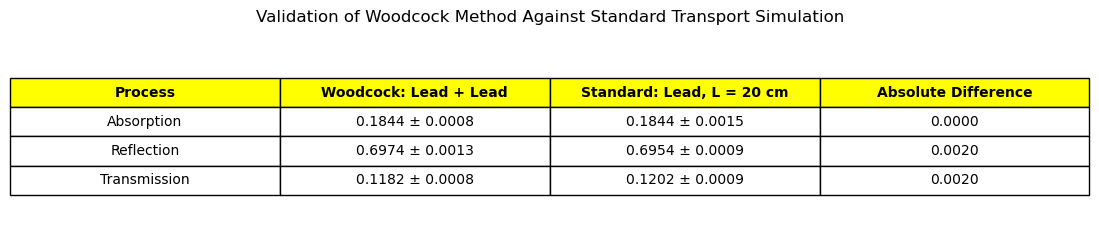

In [49]:
# Running Woodcock method for two adjacent 10 cm lead slabs.
woodcock_mean, woodcock_std, woodcock_err = repeat_woodcock(
    material_1 = woodcock_materials[validation_material],
    material_2 = woodcock_materials[validation_material],
    slab_1_thickness = 10,
    slab_2_thickness = 10,
    n_neutrons = n_neutrons,
    n_trials = n_trials
)

# Running original transport method for a single 20 cm lead slab.
standard_mean, standard_std, standard_err = repeat_transport(
    material_data = material_properties[validation_material],
    slab_thickness = 20,
    n_neutrons = n_neutrons,
    n_trials = n_trials,
    store_extra = False
)

# Defining process labels.
processes = ['Absorption', 'Reflection', 'Transmission']

# Defining an empty list to store validation table data.
validation_table = []

# Appending Woodcock and standard transport results for comparison.
for i in range(3):

    validation_table.append([
        processes[i],
        f"{woodcock_mean[i]:.4f} ± {woodcock_err[i]:.4f}",
        f"{standard_mean[i]:.4f} ± {standard_err[i]:.4f}",
        f"{abs(woodcock_mean[i] - standard_mean[i]):.4f}"
    ])

# Defining the table headers
headers = [
    'Process',
    'Woodcock: Lead + Lead',
    'Standard: Lead, L = 20 cm',
    'Absolute Difference'
]

# Creating a matplotlib figure for the table
fig, ax = plt.subplots(figsize = (11, 2.5))
# Turning off axes since only the table is required
ax.axis('off')

# Creating the table
table_plot = ax.table(cellText = validation_table, colLabels = headers, cellLoc = 'center', loc = 'center')

# Formatting the table
table_plot.auto_set_font_size(False)
table_plot.set_fontsize(10)
table_plot.scale(1.2, 1.8)

# Making the header row bold and shaded
for (row, col), cell in table_plot.get_celld().items():

    # Header row
    if row == 0:
        cell.set_text_props(weight = 'bold')
        cell.set_facecolor('yellow')

# Giving the table a title
plt.title('Validation of Woodcock Method Against Standard Transport Simulation', pad = 15)

plt.tight_layout()
plt.show()

The Woodcock result for two adjacent 10 cm lead slabs agrees with the standard transport simulation for a single 20 cm lead slab within the expected Monte Carlo uncertainty. This validates the Woodcock implementation for the case where the two materials are identical.

This is an important check because, when both slabs have the same cross-sections, the Woodcock method should reduce to the same physical problem as the original single-material transport simulation. Agreement between the two methods shows that the Woodcock code is correctly sampling step lengths, identifying material regions, applying absorption and scattering probabilities, and counting final neutron outcomes.

### 10.5 Woodcock Result for Two Adjacent Slabs

The Woodcock method is now used to simulate neutron transport through two adjacent slabs, each with thickness 10 cm. In this example, the first slab is concrete and the second slab is water. The simulation is repeated 10 times with 10000 neutrons per trial. Then, a table is produced to show the mean absorption, reflection, and transmission rates, along with the standard deviation across trials and the standard error on the mean. Note that any two materials defined in woodcock materials dictionary could be used.

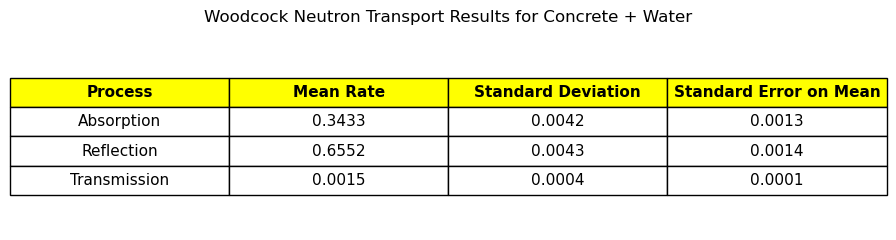

In [50]:
# Calling the function to run the simulation 10 times and extract the rates.
mean_rates, std_rates, std_error_rates = repeat_woodcock(
    woodcock_materials['Concrete'],
    woodcock_materials['Water'],
    slab_1_thickness = 10,
    slab_2_thickness = 10,
    n_neutrons = n_neutrons,
    n_trials = n_trials
)

# Defining an empty table to display the results of the simulation.
table = []

# Defining the headers.
headers = [
    'Process',
    'Mean Rate',
    'Standard Deviation',
    'Standard Error on Mean'
]

# Defining a list for the 3 outcomes to iterate over to produce the table.
processes = ['Absorption', 'Reflection', 'Transmission']

# Appending the results of the simulation for each process to the table.
for i in range(3):

    # Appending the results to the table.
    table.append([
        processes[i],
        f"{mean_rates[i]:.4f}",
        f"{std_rates[i]:.4f}",
        f"{std_error_rates[i]:.4f}"
    ])

# Creating a matplotlib figure for the table.
fig, ax = plt.subplots(figsize = (9, 2.5))

# Turning off axes since we only want the table.
ax.axis('off')

# Creating the table.
table_plot = ax.table(cellText = table, colLabels = headers, cellLoc = 'center', loc = 'center')

# Formatting the table.
table_plot.auto_set_font_size(False)
table_plot.set_fontsize(11)
table_plot.scale(1.2, 1.8)

# Making the header row bold and shaded.
for (row, col), cell in table_plot.get_celld().items():

    # Header row.
    if row == 0:
        cell.set_text_props(weight = 'bold')
        cell.set_facecolor('yellow')

# Giving a title.
plt.title('Woodcock Neutron Transport Results for Concrete + Water', pad = 15)

plt.tight_layout()
plt.show()

For the concrete + water slab combination, the transmission rate is very small. This indicates that very few neutrons pass through the full 20 cm system. Most neutrons are reflected, while a smaller but still significant fraction are absorbed inside the slabs. This behaviour is physically reasonable because the neutron must pass through two scattering media. Repeated scattering increases the probability that the neutron is redirected back towards the entrance side before it can reach the far boundary. Absorption also removes some neutrons before they can transmit.

The Woodcock method is useful here because it allows both materials to be treated within one transport algorithm, even though their total macroscopic cross-sections are different. Candidate collisions are sampled using Σmax, and the local material properties determine whether each candidate collision is real or fictitious.

## 11. Notebook Runtime

The project brief gives an expected runtime for the full notebook. The timer started at the beginning of the notebook is stopped here, and the total elapsed time is printed. This provides a check that the full simulation runs within the expected performance range.

In [51]:
# Stopping the timer once the notebook finishes running
end_time = time.time()
# Displaying the elapsed time.
print(f"Total time elapsed: {end_time - start_time:.2f} s")

Total time elapsed: 51.46 s


The full notebook was run independently 10 times to check the runtime stability. The average runtime was approximately 36.81 seconds, with individual runs varying slightly due to random sampling and system load. This places the notebook within the proficient runtime range of under 45 seconds as specified in the project brief.

## 12. Conclusion

This project used Monte Carlo methods to simulate thermal neutron transport through water, lead, and graphite. The random number generator was first validated, and exponential path-length sampling was shown to reproduce the expected absorption-only attenuation length for water of approximately 45 cm. Isotropic unit vectors and exponentially distributed step lengths were then combined to model neutron random walks.

The full slab simulation included both absorption and scattering. For L = 10 cm, water gave the lowest transmission rate because of its short total mean free path and strong scattering. Lead and graphite allowed larger transmission fractions, while lead absorbed more neutrons than graphite due to its larger absorption cross-section. Varying the slab thickness showed that transmission decreases with increasing thickness, while reflection and absorption become more significant.

Effective attenuation lengths were extracted by fitting the transmission rates as a function of slab thickness. Water had the shortest fitted attenuation length, while lead and graphite had longer attenuation lengths. These are effective transport attenuation lengths, not microscopic mean free paths, because transmission is affected by both scattering and absorption.

The stretch section implemented the Woodcock method for two adjacent slabs with different material properties. This demonstrated how virtual collisions can be used to simulate transport through non-uniform media using a single majorant cross-section.

The final runtime confirms that the notebook runs efficiently while completing the required simulations and additional diagnostic checks. Overall, this simulation successfully models the transport of thermal neutrons through shielding materials and shows how absorption, scattering, reflection, and transmission depend on material properties and slab thickness.